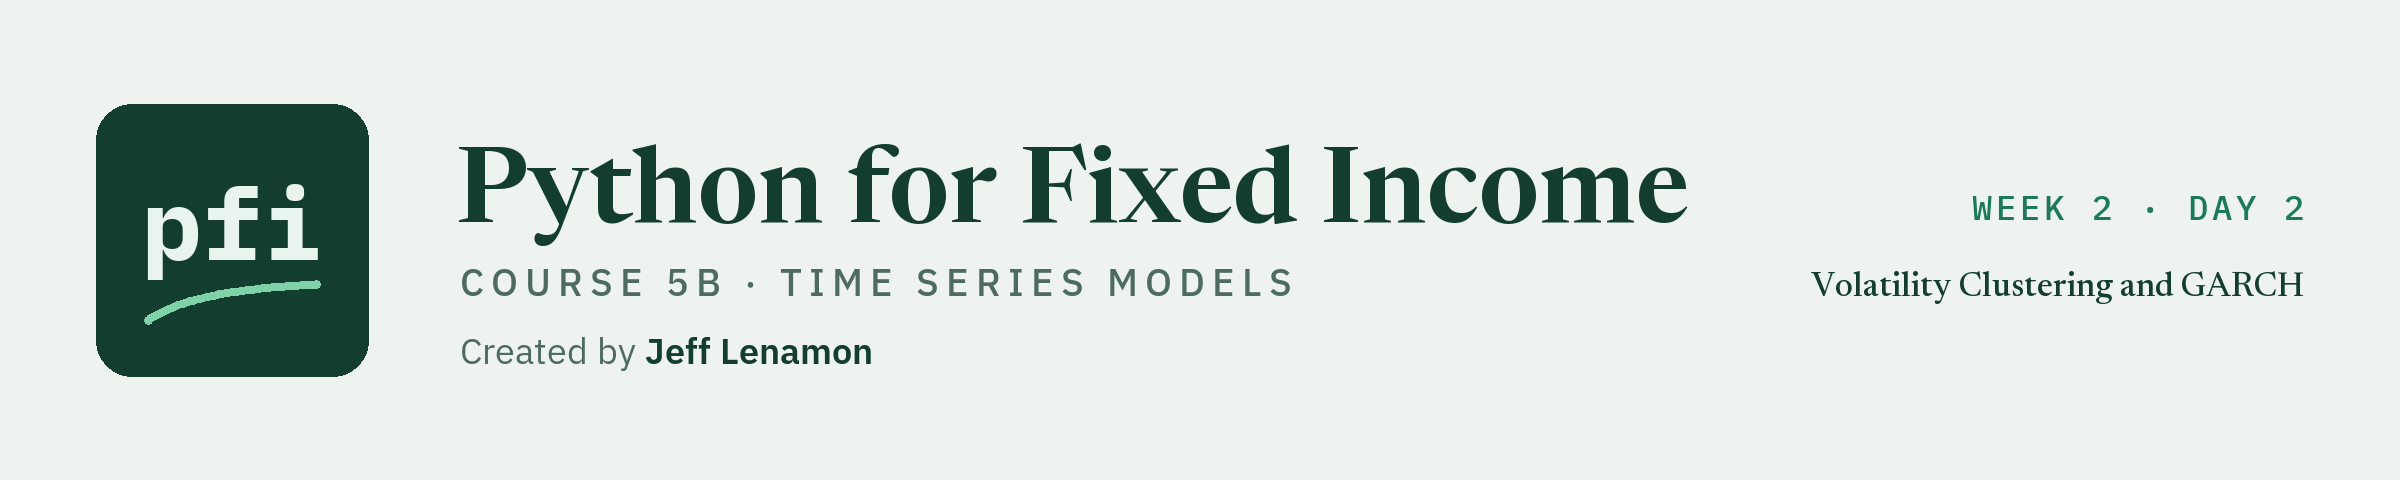

# Volatility Clustering and GARCH

Week 2, Day 2. Describe how the size of the Treasury curve's daily change comes in clusters, fit a GARCH(1,1) and read every setting, and score its one-step volatility walk-forward.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week2/day2/07_volatility_clustering_and_garch.ipynb)

Day 5 ended on a pointer. The 10 Yr's daily change has almost no memory, and the *size* of that change has a lot: the residuals of the best ARIMA were uncorrelated and their squares were not. Big days follow big days, small days follow small days, and a model that assumes shocks of a constant size cannot see it. **GARCH**, the generalised autoregressive conditional heteroskedasticity model, is the model for exactly that: it describes the *variance* of a change as a recursion on the variance before and the latest squared shock.

* **The task is in the past tense.** The model's output is a "fitted volatility": the volatility in bp that the model gives a date from the rows dated before it. Every score is walk-forward inside 2015-01-02 to 2022-12-30, from a model fitted on earlier dates only, and nothing is fitted for or reported at a later date. The held-out years stay closed until the capstone.
* **Descriptions and scores.** Sections 7.1 to 7.4 fit one GARCH to all 2,000 development changes to *describe* those years: the coefficients, the half-life of a shock, the choice of distribution. Section 7.5 *scores* it: refit on each fold's training changes, one-step volatility for each test date, day 5's folds.
* **The yardstick for the size of a change** is the absolute change. The baselines are a constant size (the training average), a 20-row average, and day 6's RiskMetrics EWMA. The one-step value for the size is the model's volatility times 0.7979, the average absolute value of a normal shock per unit of volatility.
* **Today's finding is a contrast with day 5, and a modest one.** The level of the change was no closer than the last value. The size of the change is a few percent closer than a constant for most rules and series, and the GARCH, the model built for it, is the closest rule on only one of the three series. The memory in the size is large in the data and small in the scores, and the notebook says why.

Today you will:

1. See that squared and absolute changes have long memory, and draw the calm and stormy stretches.
2. Read a GARCH(1,1): the variance recursion in one Excel formula, alpha, beta, persistence, and the half-life of a shock.
3. Draw rolling, EWMA, and GARCH volatility on one chart.
4. Read every setting of `arch_model`, and sweep the distribution, the variance model, and the order.
5. Score a walk-forward GARCH (`walk_forward_garch`) against a constant size, a 20-row average, and the EWMA.
6. Say what changed from day 5: the size of a change has memory the level does not.

Q. Set up today's work folder: the thread settings, the seed, the data files, and the modules.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course05b_time_series/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, statsmodels, arch, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("arch", "arch"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("lightgbm", "lightgbm"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course05b_time_series/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "arch": "8.0.0", "scikit-learn": "1.9.1", "lightgbm": "4.7.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5b_07_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course3_synthetic_spreads.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, arch 8.0.0, scikit-learn 1.9.1, lightgbm 4.7.0, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5b_07_ab1259f4, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course3_synthetic_spreads.csv
SEED = 42


The setup cell is the same in every Course 5B notebook. `mlkit.py`, `tskit.py`, and its tests below are the files as day 6 left them, and `plotkit.py` is the series' chart helpers, unchanged. Today appends four functions to `tskit.py`, and `arch`, the library that fits GARCH models, is one of the libraries the setup cell checks.

Q. Write `mlkit.py`, Course 4's complete module, unchanged. `tskit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `tskit.py` and `test_tskit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile tskit.py
"""tskit: the time series pieces of Course 5B, written down and tested.

Written day by day in Python for Fixed Income, Course 5B: Time Series Models.

Conventions, the same in every function:
- A series is a pandas Series, and a frame a DataFrame, indexed by date: unique and ascending.
- Yields are in percent and changes in bp, as in the Treasury file; each docstring states its unit.
- A function that describes or repairs data never fills an earlier date from a later one unless its docstring
  says so in its first lines.
- A fitted value is for a date inside the file, from a model fitted on earlier dates only; it is never a
  statement about a date after the file ends.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # dated tables

import mlkit  # Course 4's module: its walk-forward splits and its past-only check are used from day 2


def _check_dated(index: pd.Index, name: str) -> None:
    """Stop unless the index is a DatetimeIndex that is not empty, unique, and ascending."""
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{name} must be indexed by date (a DatetimeIndex)")
    if len(index) == 0:
        raise ValueError(f"{name} is empty")
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError(f"{name} must have unique dates in ascending order")


def gap_report(frame: pd.DataFrame) -> pd.DataFrame:
    """One row per column of a dated frame: where the series starts and ends, and where its values are blank.

    Input: frame, dated rows (a DatetimeIndex, unique and ascending), one column per series.
    Output: a DataFrame indexed by column name, with
      rows: the rows in the frame;
      first_valid, last_valid: the first and last dates that hold a value (NaT for a column with none);
      before_start: blank rows before first_valid (a series that had not started yet);
      blank_inside: blank cells from first_valid to last_valid (outages and gaps inside the series);
      after_end: blank rows after last_valid;
      longest_inside: the longest run of consecutive blank rows inside the series (0 when there is none).
    A date with no row at all (a market holiday) is not in the frame, so it is not counted here: compare the
    index with a calendar to find those.
    Raises ValueError for an empty frame or an index that is not dated, unique, and ascending.
    """
    _check_dated(frame.index, "frame")
    rows = []
    for column in frame.columns:
        blank = frame[column].isna().to_numpy()
        first, last = frame[column].first_valid_index(), frame[column].last_valid_index()
        if first is None:
            # no value at all: every row counts as before the start
            rows.append({"column": column, "rows": len(blank), "first_valid": pd.NaT, "last_valid": pd.NaT,
                         "before_start": len(blank), "blank_inside": 0, "after_end": 0, "longest_inside": 0})
            continue
        start, end = frame.index.get_loc(first), frame.index.get_loc(last)
        inside = blank[start:end + 1]
        runs = gap_runs(frame[column].iloc[start:end + 1]) if inside.any() else None
        rows.append({"column": column, "rows": len(blank), "first_valid": first, "last_valid": last,
                     "before_start": start, "blank_inside": int(inside.sum()), "after_end": len(blank) - 1 - end,
                     "longest_inside": int(runs["rows"].max()) if runs is not None else 0})
    return pd.DataFrame(rows).set_index("column")


def gap_runs(series: pd.Series) -> pd.DataFrame:
    """Every run of consecutive blank values in a dated series: its first and last dates and its length in rows.

    Input: series, values indexed by date (unique and ascending).
    Output: a DataFrame with one row per run, in date order, and columns
      start, end: the first and last dates of the run;
      rows: the number of blank rows in the run;
      kind: "before start" for a run on the first row (the series had not started), "after end" for a run that
      reaches the last row, and "inside" for every other run.
    With nothing blank, an empty DataFrame with the same columns. A run counts rows, not calendar days: a blank
    Friday and the blank Monday after it are one run of 2 rows.
    Raises ValueError for an empty series or an index that is not dated, unique, and ascending.
    """
    _check_dated(series.index, "series")
    blank = series.isna()
    # a new run number starts wherever blank switches between True and False
    run_number = (blank != blank.shift(fill_value=not blank.iloc[0])).cumsum()
    runs = []
    for _, run in series[blank].groupby(run_number[blank]):
        first, last = series.index.get_loc(run.index[0]), series.index.get_loc(run.index[-1])
        kind = "before start" if first == 0 else "after end" if last == len(series) - 1 else "inside"
        runs.append({"start": run.index[0], "end": run.index[-1], "rows": len(run), "kind": kind})
    return pd.DataFrame(runs, columns=["start", "end", "rows", "kind"])


def apply_corrections(frame: pd.DataFrame, corrections: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply a table of corrections to a dated frame; return the corrected copy and a log of every change.

    Inputs: frame, dated rows, one column per series; corrections, a DataFrame with the columns date, column,
    value, source: one row per cell to set. value may be NaN, to blank a value known to be wrong (DataFrame.update
    skips a NaN, so it can never blank a cell).
    Output: (corrected, log). corrected is a copy of frame; the input is not changed. log is a DataFrame with the
    columns date, column, old, new, source: one row per cell whose value changed, in the order of corrections.
    A correction that leaves a cell as it was (the same number, or blank to blank) is not a change and is not
    logged.
    Raises ValueError if corrections lacks one of its four columns, if a date or a column is not in frame, or if
    one cell is corrected twice.
    """
    _check_dated(frame.index, "frame")
    needed = ["date", "column", "value", "source"]
    missing = [name for name in needed if name not in corrections.columns]
    if missing:
        raise ValueError(f"corrections needs the columns {needed}; missing {missing}")
    dates = pd.DatetimeIndex(corrections["date"])
    unknown_dates = dates[~dates.isin(frame.index)]
    if len(unknown_dates):
        raise ValueError(f"dates not in frame: {[str(d.date()) for d in unknown_dates]}")
    unknown_columns = sorted(set(corrections["column"]) - set(frame.columns))
    if unknown_columns:
        raise ValueError(f"columns not in frame: {unknown_columns}")
    cells = list(zip(dates, corrections["column"]))
    if len(set(cells)) != len(cells):
        raise ValueError("a cell is corrected twice: one row per cell")
    corrected = frame.copy()
    log = []
    for (date, column), value, source in zip(cells, corrections["value"], corrections["source"]):
        old = corrected.at[date, column]
        # blank to blank, or the same number, is not a change
        if (pd.isna(old) and pd.isna(value)) or old == value:
            continue
        corrected.at[date, column] = value
        log.append({"date": date, "column": column, "old": old, "new": value, "source": source})
    return corrected, pd.DataFrame(log, columns=["date", "column", "old", "new", "source"])


NAIVE_KINDS = ("last", "mean", "drift")


def naive_values(series: pd.Series, kind: str, n_train: int | None = None) -> pd.Series:
    """The naive value for each date, built only from the dates before it.

    Input: series, a dated Series of levels (yields or spreads in bp); kind, one of
      "last": the value on the row before (the last value carried forward);
      "mean": the average of the values so far;
      "drift": the last value plus the average change so far;
    n_train, the rows of the training window, or None.
    Output: with n_train None, a Series on every date of the input, NaN where no earlier date exists (the first row
    for "last" and "mean", the first two rows for "drift"), each value using the dates before it. With n_train set,
    the Series for the dates from row n_train on, where "mean" and "drift" use the average level and the average
    change of the first n_train rows only, fixed for the whole test window, and "last" still uses the row before.
    Raises ValueError for an unknown kind, an input that is not dated and ascending, or an n_train outside 2 to
    one less than the rows.
    """
    _check_dated(series.index, "series")
    if kind not in NAIVE_KINDS:
        raise ValueError(f"kind must be one of {NAIVE_KINDS}, not {kind!r}")
    last = series.shift(1)
    if n_train is None:
        # expanding averages, shifted one row so a date never sees itself
        mean = series.expanding().mean().shift(1)
        change = series.diff().expanding().mean().shift(1)
        return {"last": last, "mean": mean, "drift": last + change}[kind]
    if not 2 <= n_train < len(series):
        raise ValueError(f"n_train must be from 2 to {len(series) - 1}, not {n_train}")
    train = series.iloc[:n_train]
    fixed = {"last": last, "mean": pd.Series(train.mean(), index=series.index),
             "drift": last + train.diff().mean()}[kind]
    return fixed.iloc[n_train:]


def _paired(actual, values) -> tuple[np.ndarray, np.ndarray]:
    """Two equal-length arrays with no NaN; anything else is a mistake to fix, not to hide."""
    a, v = np.asarray(actual, dtype=float), np.asarray(values, dtype=float)
    if a.shape != v.shape or a.ndim != 1 or len(a) == 0:
        raise ValueError(f"need two non-empty arrays of one length; got shapes {a.shape} and {v.shape}")
    if np.isnan(a).any() or np.isnan(v).any():
        raise ValueError("NaN in the scored values: drop those dates, or fill them on purpose, before scoring")
    return a, v


def mae(actual, values) -> float:
    """Mean absolute error: the average size of a miss, in the unit of the inputs (bp in this course)."""
    a, v = _paired(actual, values)
    return float(np.abs(a - v).mean())


def rmse(actual, values) -> float:
    """Root mean squared error, in the unit of the inputs. Squaring weights big misses more than MAE does."""
    a, v = _paired(actual, values)
    return float(np.sqrt(((a - v) ** 2).mean()))


def mase(actual, values, baseline) -> float:
    """MAE of `values` divided by the MAE of `baseline`, on the same dates (here: the last value carried forward).

    1.0 means as far from the actual values as the baseline; below 1.0 is closer. Raises ValueError if the
    baseline is exact on every date (a division by zero) or the inputs do not pair.
    """
    scale = mae(actual, baseline)
    if scale == 0:
        raise ValueError("the baseline has no error on these dates, so a ratio to it is undefined")
    return mae(actual, values) / scale


def walk_forward_score(series: pd.Series, fit_one, splits, check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score a rule fold by fold, walk-forward, and check that it uses only the past.

    Inputs: series, a dated Series with no NaN (levels in bp); fit_one(history, n_train), a function that fits on
    history.iloc[:n_train] and returns one value per row from n_train to the end of history, the value for row t
    using only rows before t; splits, the (train_positions, test_positions) list of mlkit.walk_forward_splits
    with gap 0; check, whether to prove the past-only rule by removing later rows (default True).
    Output: (scores, values). scores has one row per fold: test_start, test_end, rows, mae, rmse, all against the
    actual series. values is a Series on the series' dates, NaN outside the test windows.
    The proof: the values for the first half of each test window plus one row are recomputed with every later row
    set to NaN; a value that moves used a later row, and AssertionError names its date.
    Raises ValueError for a series with NaN, a split with a gap, or a wrong number of values.
    """
    _check_dated(series.index, "series")
    if series.isna().any():
        raise ValueError("the series has blank dates: score only dates with a value (day 1)")
    values = pd.Series(np.nan, index=series.index)
    rows = []
    for number, (train, test) in enumerate(splits, start=1):
        mlkit.assert_past_only(series.index[train], series.index[test])
        n_train, end = len(train), int(test[-1]) + 1
        if int(test[0]) != n_train:
            raise ValueError("splits must have gap 0: the test window starts on the row after training")
        history = series.iloc[:end]
        found = np.asarray(fit_one(history, n_train), dtype=float)
        if found.shape != (end - n_train,):
            raise ValueError(f"fit_one returned {found.shape} values; the test window has {end - n_train} rows")
        if check:
            # rows from the halfway row on are removed: values up to and including that row may not move
            half = n_train + len(found) // 2
            removed = history.copy()
            removed.iloc[half:] = np.nan
            again = np.asarray(fit_one(removed, n_train), dtype=float)
            moved = np.flatnonzero(~np.isclose(found[:half - n_train + 1], again[:half - n_train + 1], equal_nan=True))
            if len(moved):
                raise AssertionError(f"fold {number}: the value for {history.index[n_train + moved[0]].date()} changed "
                                     "when later rows were removed, so it used a row that is not before its date")
        actual = series.iloc[test].to_numpy()
        values.iloc[test] = found
        rows.append({"fold": number, "test_start": series.index[test[0]], "test_end": series.index[test[-1]],
                     "rows": len(test), "mae": mae(actual, found), "rmse": rmse(actual, found)})
    return pd.DataFrame(rows).set_index("fold"), values


import warnings  # kpss_summary names the one warning it handles

from statsmodels.tools.sm_exceptions import InterpolationWarning  # statsmodels' ADF and KPSS tests
from statsmodels.tsa.stattools import adfuller, kpss


def _values(series: pd.Series, name: str) -> np.ndarray:
    """The values of a Series as floats, or ValueError: a test needs at least 20 values and no blank."""
    if not isinstance(series, pd.Series):
        raise ValueError(f"{name} must be a pandas Series")
    values = series.to_numpy(dtype=float)
    if len(values) < 20:
        raise ValueError(f"{name} has {len(values)} values; a stationarity test needs at least 20")
    if np.isnan(values).any():
        raise ValueError(f"{name} has blank values: drop them first (the first change of a series is blank)")
    return values


def adf_summary(series: pd.Series, regression: str = "c", maxlag: int | None = None, autolag: str | None = "AIC") -> dict:
    """The augmented Dickey-Fuller test of a series, in a few named numbers.

    Null hypothesis: the series has a unit root (it wanders; it is not stationary). A small p-value rejects it.
    Inputs: series, values with no blank (levels or changes); regression, "c" (a constant), "ct" (a constant and a
    trend), or "n" (neither); maxlag, the most lagged changes to include (None lets statsmodels set it); autolag,
    the rule that picks the number of lagged changes up to maxlag ("AIC", "BIC", or None to use exactly maxlag).
    Output: a dict with statistic, p_value, lags_used, n_obs, critical_5pct (the 5 percent critical value), and
    rejects_unit_root (True when p_value is below 0.05).
    Raises ValueError for a series that is not a Series, has fewer than 20 values, or has a blank.
    """
    values = _values(series, "series")
    result = adfuller(values, maxlag=maxlag, regression=regression, autolag=autolag, result_object=True)
    return {"statistic": float(result.statistic), "p_value": float(result.pvalue), "lags_used": int(result.lags),
            "n_obs": int(result.nobs), "critical_5pct": float(result.critical_values["5%"]),
            "rejects_unit_root": bool(result.pvalue < 0.05)}


def kpss_summary(series: pd.Series, regression: str = "c", nlags: str | int = "auto") -> dict:
    """The KPSS test of a series, in a few named numbers.

    Null hypothesis: the series is stationary (around a constant for "c", around a trend for "ct"). A small p-value
    rejects it, which is the opposite reading of the ADF test.
    Inputs: series, values with no blank; regression, "c" or "ct"; nlags, "auto" or the number of lags in the
    long-run variance estimate.
    Output: a dict with statistic, p_value, lags_used, critical_5pct, p_note, and rejects_stationarity (True when
    p_value is below 0.05). statsmodels interpolates p-values in a table that runs from 0.01 to 0.1, so a statistic
    outside the table gives 0.01 or 0.1 exactly; p_note then says "at most 0.01" or "at least 0.1", and "inside the
    table" otherwise.
    Raises ValueError for a series that is not a Series, has fewer than 20 values, or has a blank.
    """
    values = _values(series, "series")
    # statsmodels warns when the statistic is outside its p-value table; p_note carries that information instead
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        result = kpss(values, regression=regression, nlags=nlags, result_object=True)
    p_value = float(result.pvalue)
    note = "at most 0.01" if p_value <= 0.01 else "at least 0.1" if p_value >= 0.1 else "inside the table"
    return {"statistic": float(result.statistic), "p_value": p_value, "lags_used": int(result.lags),
            "critical_5pct": float(result.critical_values["5%"]), "p_note": note, "rejects_stationarity": bool(p_value < 0.05)}


def acf_by_hand(series: pd.Series, lag: int) -> float:
    """The autocorrelation of a series at one lag, from the definition.

    The values' average is taken away; the autocorrelation at lag k is the sum, over every date that has a value k rows
    before it, of the product of the two deviations, divided by the sum of every deviation squared. It equals
    statsmodels' acf (adjusted=False), and differs a little from pandas' Series.autocorr, which takes the correlation
    of the two offset stretches.
    Inputs: series, values with no blank (changes in bp, say); lag, the rows between the two values (0 gives 1.0).
    Output: a float from -1 to 1.
    Raises ValueError for a series that is not a Series, has fewer than 3 values or a blank or no variation, or for a
    lag that is negative or not below the number of values.
    """
    if not isinstance(series, pd.Series):
        raise ValueError("series must be a pandas Series")
    values = series.to_numpy(dtype=float)
    if len(values) < 3:
        raise ValueError(f"series has {len(values)} values; an autocorrelation needs at least 3")
    if np.isnan(values).any():
        raise ValueError("series has blank values: drop them first (the first change of a series is blank)")
    if not 0 <= lag < len(values):
        raise ValueError(f"lag must be from 0 to {len(values) - 1}; got {lag}")
    deviations = values - values.mean()
    total = float((deviations ** 2).sum())
    if total == 0:
        raise ValueError("series does not vary, so its autocorrelation is undefined")
    return float((deviations[lag:] * deviations[:len(values) - lag]).sum() / total)


from statsmodels.tools.sm_exceptions import EstimationWarning  # the one warning fit_arima handles
from statsmodels.tsa.arima.model import ARIMA


def fit_arima(values, order: tuple, trend: str = "c", require_convergence: bool = True, **settings):
    """Fit an ARIMA(p, d, q) by maximum likelihood to a plain array and return statsmodels' results.

    Inputs: values, a one-dimensional array of floats with no blank (daily changes in bp, say); order, the tuple (p, d, q);
    trend, "n" (none), "c" (a constant), "t" (a time trend), or "ct"; require_convergence, whether to raise if the
    optimiser did not converge (the default) or return the results anyway, for a grid that records `converged`;
    settings, any other ARIMA setting by name (enforce_stationarity=False, say).
    Output: the fitted results; results.mle_retvals["converged"] says whether the optimiser converged.
    The array goes in without its dates on purpose: a series of trading days has no frequency, and statsmodels warns
    about a date index it cannot use. Two statsmodels messages are handled here and nowhere else: the optimiser's
    ConvergenceWarning is switched off through method_kwargs (the result says so instead), and the EstimationWarning
    "starting parameters replaced by zeros", which reports a fallback for mixed AR and MA orders, is caught.
    Raises ValueError for an order that is not three non-negative integers or values with a blank, and RuntimeError when
    require_convergence is True and the optimiser did not converge.
    """
    if len(order) != 3 or not all(isinstance(k, (int, np.integer)) and k >= 0 for k in order):
        raise ValueError(f"order must be three non-negative integers (p, d, q); got {order}")
    array = np.asarray(values, dtype=float)
    if array.ndim != 1 or len(array) < 10 or np.isnan(array).any():
        raise ValueError("values must be a one-dimensional array of at least 10 numbers with no blank")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", EstimationWarning)
        results = ARIMA(array, order=order, trend=trend, **settings).fit(method_kwargs={"warn_convergence": False})
    if require_convergence and not results.mle_retvals["converged"]:
        raise RuntimeError(f"ARIMA{tuple(order)} did not converge on {len(array)} values: try a smaller order")
    return results


def arima_grid(values, max_p: int, max_q: int, trend: str = "c") -> pd.DataFrame:
    """The information criteria of every ARIMA(p, 0, q) with p up to max_p and q up to max_q, on one array.

    Input: values, as for fit_arima (a stationary series: a change, not a level); trend as for fit_arima.
    Output: a DataFrame with one row per (p, q), in order, and the columns p, q, aic, bic, converged. AIC is
    2k - 2 ln L and BIC is k ln(n) - 2 ln L, with k fitted parameters (including the variance) and L the likelihood:
    lower is better, and BIC charges more per parameter. A fit that did not converge keeps its row, with converged False.
    Only criteria of fits to the same values can be compared.
    """
    rows = []
    for p in range(max_p + 1):
        for q in range(max_q + 1):
            results = fit_arima(values, (p, 0, q), trend=trend, require_convergence=False)
            rows.append({"p": p, "q": q, "aic": float(results.aic), "bic": float(results.bic),
                         "converged": bool(results.mle_retvals["converged"])})
    return pd.DataFrame(rows)


def walk_forward_arima(series: pd.Series, order: tuple, splits, trend: str = "c", check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score an ARIMA's one-step values fold by fold, walk-forward, with the past-only proof of walk_forward_score.

    Inputs: series, a dated Series with no NaN, the series the ARIMA is fitted to (daily changes in bp for a stationary
    model, order (p, 0, q)); order, the tuple (p, d, q); splits, from mlkit.walk_forward_splits with gap 0 and positions in
    this series; trend, as for fit_arima; check, as for walk_forward_score.
    Each fold fits the ARIMA once, on its training rows only, then gives the model's value for every test row: the
    fitted model is run over the test rows with .append(..., refit=False), whose .predict gives the one-step value for each
    row from the rows before it. The parameters do not change inside a fold, and are refitted at the next fold.
    Output: (scores, values), as walk_forward_score returns them: the MAE and RMSE of each fold against the actual series,
    and the model's value for every test date.
    Raises what fit_arima and walk_forward_score raise (RuntimeError if a fold's fit does not converge).
    """
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the fit uses only the training rows, so it is shared by the proof's second run
        if n_train not in fitted:
            fitted[n_train] = fit_arima(history.iloc[:n_train].to_numpy(), order, trend=trend)
        run = fitted[n_train].append(history.iloc[n_train:].to_numpy(), refit=False)
        return np.asarray(run.predict(start=n_train, end=len(history) - 1), dtype=float)

    return walk_forward_score(series, fit_one, splits, check=check)


from statsmodels.tsa.holtwinters import ExponentialSmoothing


def ewma(series: pd.Series, alpha: float) -> pd.Series:
    """The exponentially weighted moving average of a series, one recursive step per row.

    Input: series, a dated Series with no blank (levels in bp, or squared changes); alpha, the weight on the newest
    row, above 0 and up to 1 (1 gives the series back; a small alpha gives a slow average).
    Output: a Series on the same dates with s[0] = x[0] and s[t] = alpha x[t] + (1 - alpha) s[t-1], which is
    pandas' ewm(alpha=alpha, adjust=False).mean(). The value on a date uses that date's row and the rows before it;
    to use it as a value for a date, shift it down one row.
    Raises ValueError for an alpha outside (0, 1], an empty series, or a blank.
    """
    if not 0 < alpha <= 1:
        raise ValueError(f"alpha must be above 0 and at most 1, not {alpha}")
    values = series.to_numpy(dtype=float)
    if len(values) == 0 or np.isnan(values).any():
        raise ValueError("the series must have at least one row and no blank")
    smoothed = np.empty(len(values))
    smoothed[0] = values[0]
    for row in range(1, len(values)):
        smoothed[row] = alpha * values[row] + (1 - alpha) * smoothed[row - 1]
    return pd.Series(smoothed, index=series.index)


def smoothing_values(values, level0: float, alpha: float, trend0: float = 0.0, beta: float = 0.0, phi: float = 1.0) -> np.ndarray:
    """The one-step value of an exponential smoothing for every row, by the recursion, from fixed coefficients.

    Inputs: values, a one-dimensional array of levels in bp (a NaN stops the recursion from that row on); level0 and
    trend0, the state before the first row; alpha, beta, and phi, the weights on the newest level, on the newest trend,
    and the damping of the trend (1 means no damping). With trend0 = 0 and beta = 0 this is simple smoothing.
    Output: an array the length of values. Entry t is level[t-1] + phi x trend[t-1], the value for row t given only the
    rows before it, where level[t] = alpha x[t] + (1 - alpha)(level[t-1] + phi trend[t-1]) and
    trend[t] = beta (level[t] - level[t-1]) + (1 - beta) phi trend[t-1].
    """
    array = np.asarray(values, dtype=float)
    out = np.empty(len(array))
    level, trend = level0, trend0
    for row in range(len(array)):
        out[row] = level + phi * trend
        new_level = alpha * array[row] + (1 - alpha) * (level + phi * trend)
        trend = beta * (new_level - level) + (1 - beta) * phi * trend
        level = new_level
    return out


def fit_smoothing(values, trend: str | None = None, damped: bool = False, **settings):
    """Fit an exponential smoothing by least squares to a plain array and return statsmodels' results.

    Inputs: values, a one-dimensional array of floats with no blank (levels in bp); trend, None for simple smoothing
    or "add" for Holt's linear trend; damped, whether the trend is damped (needs trend="add"); settings, any other
    ExponentialSmoothing setting by name (initialization_method, bounds). The starting level and trend are estimated
    along with the weights, from these values only.
    Output: the fitted results; results.params holds smoothing_level, smoothing_trend, damping_trend, initial_level,
    and initial_trend (nan for a part the model does not have).
    The array goes in without its dates for the reason fit_arima gives: a series of trading days has no frequency.
    Raises ValueError for values with a blank or fewer than 10 numbers.
    """
    array = np.asarray(values, dtype=float)
    if array.ndim != 1 or len(array) < 10 or np.isnan(array).any():
        raise ValueError("values must be a one-dimensional array of at least 10 numbers with no blank")
    settings.setdefault("initialization_method", "estimated")
    return ExponentialSmoothing(array, trend=trend, damped_trend=damped, **settings).fit()


def walk_forward_smoothing(series: pd.Series, splits, trend: str | None = None, damped: bool = False,
                           check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score an exponential smoothing's one-step values fold by fold, walk-forward, with walk_forward_score's proof.

    Inputs: series, a dated Series of levels in bp with no NaN; splits, from mlkit.walk_forward_splits with gap 0;
    trend and damped, as for fit_smoothing; check, as for walk_forward_score.
    Each fold fits the weights and the starting state on its training rows only, then runs the recursion
    (smoothing_values) over the training rows and on through the fold's rows with those weights held fixed: the value
    for a test row uses only the rows before it. The weights are fitted again at the next fold.
    Output: (scores, values), as walk_forward_score returns them. The level folds are day 2's, so the last value
    carried forward scores day 2's numbers on the same dates.
    """
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the fit uses only the training rows, so it is shared by the proof's second run
        if n_train not in fitted:
            fitted[n_train] = fit_smoothing(history.iloc[:n_train].to_numpy(), trend=trend, damped=damped).params
        p = fitted[n_train]
        trended = trend is not None
        found = smoothing_values(history.to_numpy(), p["initial_level"], p["smoothing_level"],
                                 trend0=float(p["initial_trend"]) if trended else 0.0,
                                 beta=float(p["smoothing_trend"]) if trended else 0.0,
                                 phi=float(p["damping_trend"]) if damped else 1.0)
        return found[n_train:]

    return walk_forward_score(series, fit_one, splits, check=check)

Writing tskit.py


In [5]:
%%writefile test_tskit.py
"""Tests for tskit, written day by day in Course 5B. Small seeded arrays only: no data file is read."""
import numpy as np
import pandas as pd
import pytest

import tskit


def dated_frame() -> pd.DataFrame:
    """Ten business days and two seeded columns of yields in percent. Column a starts on the third day and has a
    two-day blank inside (days 5 and 6, a Friday and a Monday); column b has a value on every day."""
    rng = np.random.default_rng(42)
    dates = pd.bdate_range("2024-01-01", periods=10)
    frame = pd.DataFrame({"a": rng.normal(4.0, 0.1, 10), "b": rng.normal(4.5, 0.1, 10)}, index=dates)
    frame.iloc[:2, 0] = np.nan
    frame.iloc[4:6, 0] = np.nan
    return frame


def test_gap_report_counts():
    report = tskit.gap_report(dated_frame())
    a, b = report.loc["a"], report.loc["b"]
    assert (a["rows"], a["before_start"], a["blank_inside"], a["after_end"], a["longest_inside"]) == (10, 2, 2, 0, 2)
    assert a["first_valid"] == pd.Timestamp("2024-01-03")
    assert (b["before_start"], b["blank_inside"], b["longest_inside"]) == (0, 0, 0)


def test_gap_report_refuses_unsorted_dates():
    frame = dated_frame()
    with pytest.raises(ValueError, match="ascending"):
        tskit.gap_report(frame.iloc[::-1])
    with pytest.raises(ValueError, match="DatetimeIndex"):
        tskit.gap_report(frame.reset_index(drop=True))


def test_gap_runs_kinds_and_lengths():
    runs = tskit.gap_runs(dated_frame()["a"])
    assert runs["rows"].tolist() == [2, 2]
    assert runs["kind"].tolist() == ["before start", "inside"]
    # a Friday and the Monday after it are one run of two rows
    assert runs["start"].iloc[1] == pd.Timestamp("2024-01-05") and runs["end"].iloc[1] == pd.Timestamp("2024-01-08")
    series = dated_frame()["b"]
    series.iloc[-3:] = np.nan
    assert tskit.gap_runs(series)["kind"].tolist() == ["after end"]


def test_gap_runs_none_blank():
    runs = tskit.gap_runs(dated_frame()["b"])
    assert runs.empty and runs.columns.tolist() == ["start", "end", "rows", "kind"]


def test_apply_corrections_logs_and_copies():
    frame = dated_frame()
    day = frame.index[3]
    corrections = pd.DataFrame({"date": [day, frame.index[4]], "column": ["b", "b"],
                                "value": [9.99, frame.at[frame.index[4], "b"]], "source": ["desk", "desk"]})
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert corrected.at[day, "b"] == 9.99 and frame.at[day, "b"] != 9.99
    # the second correction changes nothing, so only the first is logged
    assert log[["column", "new", "source"]].values.tolist() == [["b", 9.99, "desk"]]
    assert log["old"].iloc[0] == frame.at[day, "b"]


def test_apply_corrections_blanks_where_update_does_not():
    frame = dated_frame()
    day = frame.index[8]
    corrections = pd.DataFrame({"date": [day], "column": ["b"], "value": [np.nan], "source": ["desk"]})
    updated = frame.copy()
    updated.update(corrections.pivot(index="date", columns="column", values="value"))
    assert updated.at[day, "b"] == frame.at[day, "b"]
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert np.isnan(corrected.at[day, "b"]) and len(log) == 1 and np.isnan(log["new"].iloc[0])


def test_apply_corrections_refusals():
    frame = dated_frame()
    good = {"date": [frame.index[0]], "column": ["b"], "value": [4.0], "source": ["desk"]}
    with pytest.raises(ValueError, match="missing"):
        tskit.apply_corrections(frame, pd.DataFrame(good).drop(columns="source"))
    with pytest.raises(ValueError, match="dates not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"date": [pd.Timestamp("2024-01-06")]}))
    with pytest.raises(ValueError, match="columns not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"column": ["c"]}))
    with pytest.raises(ValueError, match="twice"):
        tskit.apply_corrections(frame, pd.concat([pd.DataFrame(good)] * 2))


def levels_series() -> pd.Series:
    """Five business days of a hand-checkable level series: 1, 2, 4, 7, 11 (the changes 1, 2, 3, 4)."""
    return pd.Series([1.0, 2.0, 4.0, 7.0, 11.0], index=pd.bdate_range("2024-01-01", periods=5))


def seeded_walk(rows: int = 40) -> pd.Series:
    """A seeded random walk in bp on business days."""
    rng = np.random.default_rng(42)
    return pd.Series(100.0 + rng.normal(0.0, 2.0, rows).cumsum(), index=pd.bdate_range("2024-01-01", periods=rows))


def last_value(history, n_train):
    return tskit.naive_values(history, "last", n_train).to_numpy()


def test_naive_values_use_only_earlier_dates():
    series = levels_series()
    last = tskit.naive_values(series, "last")
    mean = tskit.naive_values(series, "mean")
    drift = tskit.naive_values(series, "drift")
    assert np.isnan(last.iloc[0]) and last.iloc[1:].tolist() == [1.0, 2.0, 4.0, 7.0]
    assert np.isnan(mean.iloc[0]) and mean.iloc[1:].tolist() == pytest.approx([1.0, 1.5, 7 / 3, 3.5])
    # the last value plus the average change so far: 2 + 1, 4 + 1.5, 7 + 2
    assert drift.iloc[:2].isna().all() and drift.iloc[2:].tolist() == pytest.approx([3.0, 5.5, 9.0])
    # changing the last row moves no value dated before it
    other = series.copy()
    other.iloc[-1] = 99.0
    for kind in tskit.NAIVE_KINDS:
        assert tskit.naive_values(other, kind).iloc[:-1].equals(tskit.naive_values(series, kind).iloc[:-1])


def test_naive_values_with_a_training_window():
    series = levels_series()
    # the first 3 rows: mean level 7/3, average change 1.5, both fixed over the test window
    assert tskit.naive_values(series, "last", 3).tolist() == [4.0, 7.0]
    assert tskit.naive_values(series, "mean", 3).tolist() == pytest.approx([7 / 3, 7 / 3])
    assert tskit.naive_values(series, "drift", 3).tolist() == pytest.approx([5.5, 8.5])
    with pytest.raises(ValueError, match="kind"):
        tskit.naive_values(series, "median")
    with pytest.raises(ValueError, match="n_train"):
        tskit.naive_values(series, "last", 5)


def test_mae_rmse_mase_by_hand():
    actual, values, baseline = [1.0, 2.0, 3.0, 4.0], [1.0, 3.0, 3.0, 2.0], [2.0, 2.0, 5.0, 4.0]
    assert tskit.mae(actual, values) == 0.75
    assert tskit.rmse(actual, values) == pytest.approx(np.sqrt(5 / 4))
    # the baseline misses by 1, 0, 2, 0: MAE 0.75, so the ratio is exactly 1
    assert tskit.mase(actual, values, baseline) == 1.0
    assert tskit.mase(actual, actual, baseline) == 0.0
    assert tskit.mase(actual, baseline, values) == 1.0


def test_scoring_refuses_what_it_cannot_score():
    with pytest.raises(ValueError, match="NaN"):
        tskit.mae([1.0, np.nan], [1.0, 2.0])
    with pytest.raises(ValueError, match="one length"):
        tskit.rmse([1.0, 2.0], [1.0])
    with pytest.raises(ValueError, match="undefined"):
        tskit.mase([1.0, 2.0], [1.5, 2.5], [1.0, 2.0])


def test_walk_forward_score_last_value():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)
    scores, values = tskit.walk_forward_score(series, last_value, splits)
    assert len(scores) == 2 and scores["rows"].tolist() == [10, 10]
    # the last value's miss is the change itself
    changes = series.diff().abs()
    assert scores["mae"].iloc[0] == pytest.approx(changes.iloc[20:30].mean())
    assert values.iloc[:20].isna().all() and values.iloc[20:40].notna().all()
    assert values.iloc[25] == series.iloc[24]


def test_walk_forward_score_catches_a_later_row():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)

    def same_day(history, n_train):
        # the value for a date is the date's own value
        return history.iloc[n_train:].to_numpy()

    def whole_window_mean(history, n_train):
        # every value uses the mean of the whole test window, later rows included
        return np.full(len(history) - n_train, history.mean())

    with pytest.raises(AssertionError, match="later rows"):
        tskit.walk_forward_score(series, same_day, splits)
    with pytest.raises(AssertionError, match="later rows"):
        tskit.walk_forward_score(series, whole_window_mean, splits)
    # with the proof off, the cheat scores perfectly: that is why the proof is on by default
    scores, _ = tskit.walk_forward_score(series, same_day, splits, check=False)
    assert scores["mae"].max() == 0.0


def test_walk_forward_score_refusals():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)
    blank = series.copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="blank"):
        tskit.walk_forward_score(blank, last_value, splits)
    gapped = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=5, gap=2)
    with pytest.raises(ValueError, match="gap 0"):
        tskit.walk_forward_score(series, last_value, gapped)
    with pytest.raises(ValueError, match="values"):
        tskit.walk_forward_score(series, lambda history, n_train: np.zeros(3), splits)


def walk_and_noise() -> tuple[pd.Series, pd.Series]:
    """A seeded random walk and seeded white noise, 500 values each."""
    rng = np.random.default_rng(42)
    noise = pd.Series(rng.standard_normal(500))
    return noise.cumsum(), noise


def test_adf_summary_walk_and_noise():
    walk, noise = walk_and_noise()
    on_walk, on_noise = tskit.adf_summary(walk), tskit.adf_summary(noise)
    # a random walk has a unit root: the test does not reject it; noise does not: the test rejects
    assert not on_walk["rejects_unit_root"] and on_walk["p_value"] > 0.05
    assert on_noise["rejects_unit_root"] and on_noise["p_value"] < 0.001
    assert on_walk["statistic"] > on_walk["critical_5pct"] and on_noise["statistic"] < on_noise["critical_5pct"]


def test_adf_with_no_lags_is_a_regression():
    walk, _ = walk_and_noise()
    summary = tskit.adf_summary(walk, regression="c", maxlag=0, autolag=None)
    # the change on its lagged level and a constant: the statistic is the slope divided by its standard error
    y = walk.to_numpy()
    X = np.column_stack([np.ones(len(y) - 1), y[:-1]])
    target = np.diff(y)
    beta, *_ = np.linalg.lstsq(X, target, rcond=None)
    resid = target - X @ beta
    se = np.sqrt(resid @ resid / (len(target) - 2) * np.linalg.inv(X.T @ X)[1, 1])
    assert summary["statistic"] == pytest.approx(beta[1] / se)
    assert summary["lags_used"] == 0 and summary["n_obs"] == len(target)


def test_kpss_summary_reads_the_other_way():
    walk, noise = walk_and_noise()
    on_walk, on_noise = tskit.kpss_summary(walk), tskit.kpss_summary(noise)
    # KPSS rejects stationarity for the walk and does not for the noise, the reverse of ADF's reading
    assert on_walk["rejects_stationarity"] and not on_noise["rejects_stationarity"]
    assert on_walk["p_note"] in ("at most 0.01", "inside the table") and on_noise["p_note"] == "at least 0.1"
    assert on_noise["p_value"] == 0.1


def test_summaries_refuse_bad_input():
    walk, _ = walk_and_noise()
    blank = walk.copy()
    blank.iloc[3] = np.nan
    for function in (tskit.adf_summary, tskit.kpss_summary):
        with pytest.raises(ValueError, match="blank"):
            function(blank)
        with pytest.raises(ValueError, match="at least 20"):
            function(walk.iloc[:10])
        with pytest.raises(ValueError, match="Series"):
            function(walk.to_numpy())


def test_acf_by_hand_on_five_numbers():
    series = pd.Series([1.0, 2.0, 3.0, 4.0, 5.0])
    # deviations -2 -1 0 1 2, their squares sum to 10: lag 1 gives 4 / 10, lag 2 gives -1 / 10
    assert tskit.acf_by_hand(series, 0) == 1.0
    assert tskit.acf_by_hand(series, 1) == pytest.approx(0.4)
    assert tskit.acf_by_hand(series, 2) == pytest.approx(-0.1)


def test_acf_by_hand_equals_statsmodels():
    from statsmodels.tsa.stattools import acf
    rng = np.random.default_rng(42)
    shocks = rng.standard_normal(300)
    series = pd.Series(shocks[1:] + 0.5 * shocks[:-1])
    library = acf(series, nlags=8, result_object=False)
    assert [tskit.acf_by_hand(series, lag) for lag in range(9)] == pytest.approx(library, abs=1e-12)
    # the same on a series with a date index: only the values matter
    dated = series.set_axis(pd.bdate_range("2024-01-01", periods=len(series)))
    assert tskit.acf_by_hand(dated, 3) == pytest.approx(library[3], abs=1e-12)


def test_acf_by_hand_refusals():
    series = pd.Series([1.0, 2.0, 4.0, 3.0, 5.0])
    with pytest.raises(ValueError, match="lag must be"):
        tskit.acf_by_hand(series, 5)
    with pytest.raises(ValueError, match="lag must be"):
        tskit.acf_by_hand(series, -1)
    with pytest.raises(ValueError, match="blank"):
        tskit.acf_by_hand(series.where(series != 4.0), 1)
    with pytest.raises(ValueError, match="does not vary"):
        tskit.acf_by_hand(pd.Series([2.0] * 5), 1)
    with pytest.raises(ValueError, match="at least 3"):
        tskit.acf_by_hand(series.iloc[:2], 1)
    with pytest.raises(ValueError, match="Series"):
        tskit.acf_by_hand(series.to_numpy(), 1)


def ar1_series(rows: int = 600, phi: float = 0.6) -> pd.Series:
    """A seeded AR(1) of daily changes in bp on business days."""
    rng = np.random.default_rng(42)
    shocks = rng.standard_normal(rows)
    values = np.zeros(rows)
    for row in range(1, rows):
        values[row] = phi * values[row - 1] + shocks[row]
    return pd.Series(values, index=pd.bdate_range("2020-01-01", periods=rows))


def test_fit_arima_recovers_an_ar1():
    results = tskit.fit_arima(ar1_series().to_numpy(), (1, 0, 0))
    constant, phi, variance = results.params
    # 600 seeded values: the coefficient is near the 0.6 that made them
    assert phi == pytest.approx(0.6, abs=0.1) and variance == pytest.approx(1.0, abs=0.25)
    assert results.mle_retvals["converged"]


def test_arima_grid_bic_picks_the_ar1():
    grid = tskit.arima_grid(ar1_series().to_numpy(), 2, 2)
    assert len(grid) == 9 and grid["converged"].all()
    best = grid.loc[grid["bic"].idxmin()]
    assert (best["p"], best["q"]) == (1, 0)


def test_walk_forward_arima_of_order_zero_is_the_training_mean():
    series = ar1_series(rows=140)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=80, test_size=30)
    scores, values = tskit.walk_forward_arima(series, (0, 0, 0), splits)
    for train, test in splits:
        assert values.iloc[test].to_numpy() == pytest.approx(series.iloc[train].mean(), abs=1e-4)
    assert len(scores) == 2 and scores["rows"].tolist() == [30, 30]


def test_walk_forward_arima_uses_only_the_past():
    series = ar1_series(rows=140)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=80, test_size=30)
    _, values = tskit.walk_forward_arima(series, (1, 0, 0), splits)
    # change every row from position 100 on: no value dated before position 100 may move
    other = series.copy()
    other.iloc[100:] = other.iloc[100:] + 5.0
    _, again = tskit.walk_forward_arima(other, (1, 0, 0), splits, check=False)
    assert values.iloc[:100].equals(again.iloc[:100])
    assert not values.iloc[100:110].equals(again.iloc[100:110])


def test_walk_forward_arima_beats_the_mean_on_an_ar1():
    series = ar1_series()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=300, test_size=100)
    model, _ = tskit.walk_forward_arima(series, (1, 0, 0), splits)
    mean, _ = tskit.walk_forward_arima(series, (0, 0, 0), splits)
    assert (model["mae"] < mean["mae"]).all()


def test_arima_refusals():
    values = ar1_series().to_numpy()
    with pytest.raises(ValueError, match="three non-negative"):
        tskit.fit_arima(values, (1, 0))
    with pytest.raises(ValueError, match="three non-negative"):
        tskit.fit_arima(values, (1, -1, 0))
    blank = values.copy()
    blank[3] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_arima(blank, (1, 0, 0))


def level_series(rows: int = 400) -> pd.Series:
    """A seeded level that wanders slowly, plus noise, in bp on business days."""
    rng = np.random.default_rng(7)
    level = 100.0 + np.cumsum(rng.normal(0.0, 0.3, rows))
    return pd.Series(level + rng.normal(0.0, 2.0, rows), index=pd.bdate_range("2020-01-01", periods=rows))


def test_ewma_equals_pandas_and_alpha_one_is_the_series():
    series = level_series()
    for alpha in (0.05, 0.3, 0.9):
        assert tskit.ewma(series, alpha).to_numpy() == pytest.approx(series.ewm(alpha=alpha, adjust=False).mean().to_numpy(), abs=1e-10)
    assert tskit.ewma(series, 1.0).equals(series)


def test_ewma_refusals():
    series = level_series(rows=20)
    for alpha in (0.0, -0.1, 1.5):
        with pytest.raises(ValueError, match="alpha"):
            tskit.ewma(series, alpha)
    blank = series.copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.ewma(blank, 0.5)


def test_smoothing_values_equal_statsmodels_fitted_values():
    values = level_series().to_numpy()
    for trend, damped in ((None, False), ("add", False), ("add", True)):
        results = tskit.fit_smoothing(values, trend=trend, damped=damped)
        p = results.params
        found = tskit.smoothing_values(values, p["initial_level"], p["smoothing_level"],
                                       trend0=float(p["initial_trend"]) if trend else 0.0,
                                       beta=float(p["smoothing_trend"]) if trend else 0.0,
                                       phi=float(p["damping_trend"]) if damped else 1.0)
        assert found == pytest.approx(results.fittedvalues, abs=1e-6)


def test_simple_smoothing_with_alpha_one_is_the_last_value():
    values = level_series(rows=50).to_numpy()
    found = tskit.smoothing_values(values, values[0], 1.0)
    assert found[1:] == pytest.approx(values[:-1], abs=1e-12)


def test_walk_forward_smoothing_uses_only_the_past():
    series = level_series(rows=200)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=100, test_size=40)
    _, values = tskit.walk_forward_smoothing(series, splits)
    # change every row from position 150 on: no value dated before position 150 may move
    other = series.copy()
    other.iloc[150:] = other.iloc[150:] + 20.0
    _, again = tskit.walk_forward_smoothing(other, splits, check=False)
    assert values.iloc[:150].equals(again.iloc[:150])
    assert not values.iloc[150:160].equals(again.iloc[150:160])


def test_smoothing_beats_the_last_value_on_a_noisy_level():
    series = level_series(rows=500)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=200, test_size=100)
    smooth, _ = tskit.walk_forward_smoothing(series, splits)
    last = [tskit.mae(series.iloc[test], series.shift(1).iloc[test]) for _, test in splits]
    assert (smooth["mae"].to_numpy() < np.array(last)).all()


def test_fit_smoothing_refusals():
    values = level_series().to_numpy()
    blank = values.copy()
    blank[5] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_smoothing(blank)
    with pytest.raises(ValueError, match="at least 10"):
        tskit.fit_smoothing(values[:5])

Writing test_tskit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import tskit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(tskit)

# the functions defined in tskit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(tskit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "tskit" and not name.startswith("_")]
print(f"tskit functions: {functions}")

tskit functions: ['gap_report', 'gap_runs', 'apply_corrections', 'naive_values', 'mae', 'rmse', 'mase', 'walk_forward_score', 'adf_summary', 'kpss_summary', 'acf_by_hand', 'fit_arima', 'arima_grid', 'walk_forward_arima', 'ewma', 'smoothing_values', 'fit_smoothing', 'walk_forward_smoothing']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


Q. Load the five series in bp on the development years, as days 2 to 6 did.

In [9]:
# the Treasury curve (percent) and the course's synthetic spreads (bp): one row per date, the same dates in both files
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"]).set_index("date")
print(f"Treasury file: {len(treasury):,} dates; spread file: {len(spreads):,} dates; same dates: {treasury.index.equals(spreads.index)}")

# the development and held-out years, set now, before any model is fitted
DEVELOPMENT_END = "2022-12-30"
development = treasury.loc[:DEVELOPMENT_END]
dev_spreads = spreads.loc[:DEVELOPMENT_END]
held_out_dates = treasury.index[treasury.index > DEVELOPMENT_END]
print(f"development years: {len(development):,} dates, {development.index[0].date()} to {development.index[-1].date()}")
print(f"held-out years: {len(held_out_dates):,} dates, {held_out_dates[0].date()} to {held_out_dates[-1].date()}, not opened until the capstone")

# five series, all in bp: yields times 100 (rounded to the file's two decimals of a percent), spreads as they are
levels = pd.DataFrame({
    "2 Yr": (development["2 Yr"] * 100).round(2),
    "10 Yr": (development["10 Yr"] * 100).round(2),
    "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
    "IG": dev_spreads["ig_spread_bp"],
    "HY": dev_spreads["hy_spread_bp"],
})
# nothing below reads a held-out row: drop the full tables
del treasury, spreads, development, dev_spreads
print(f"five series in bp: {list(levels.columns)}; blank cells: {int(levels.isna().sum().sum())}")

# the walk-forward windows of section 2.5, used by every later day: fit on 504 dates first, then score 252 at a time
MIN_TRAIN, TEST_SIZE = 504, 252

Treasury file: 2,940 dates; spread file: 2,940 dates; same dates: True
development years: 2,001 dates, 2015-01-02 to 2022-12-30
held-out years: 939 dates, 2023-01-03 to 2026-10-02, not opened until the capstone
five series in bp: ['2 Yr', '10 Yr', '2s10s', 'IG', 'HY']; blank cells: 0


* The same cell: 2,001 development dates, five series, and no way to reach a held-out row.

Q. Make day 2's five folds for the **changes** as day 5 did (positions one row later), and the constant size in each fold.

In [10]:
# day 2's folds on the levels' dates; the change series starts one row later, so each fold's positions shift down by one
changes = levels.diff().dropna()
level_splits = mlkit.walk_forward_splits(levels.index, min_train=MIN_TRAIN, test_size=TEST_SIZE)
splits = [(train[1:] - 1, test - 1) for train, test in level_splits]
for number, (train, test) in enumerate(splits, start=1):
    mlkit.assert_past_only(changes.index[train], changes.index[test])
    print(f"fold {number}: fit on {len(train)} changes to {changes.index[train[-1]].date()}, "
          f"score {len(test)} from {changes.index[test[0]].date()} to {changes.index[test[-1]].date()}")

# the size of a change is its absolute value: the average size in each fold is the constant day 2's MAE of a zero change measures
size_mae = pd.DataFrame({column: [changes[column].iloc[test].abs().mean() for _, test in splits] for column in changes.columns},
                        index=pd.Index(range(1, len(splits) + 1), name="fold"))
print(size_mae.mean().round(4).to_string())

fold 1: fit on 503 changes to 2017-01-05, score 252 from 2017-01-06 to 2018-01-08
fold 2: fit on 755 changes to 2018-01-08, score 252 from 2018-01-09 to 2019-01-11
fold 3: fit on 1007 changes to 2019-01-11, score 252 from 2019-01-14 to 2020-01-15
fold 4: fit on 1259 changes to 2020-01-15, score 252 from 2020-01-16 to 2021-01-19
fold 5: fit on 1511 changes to 2021-01-19, score 252 from 2021-01-20 to 2022-01-19
2 Yr     2.1881
10 Yr    3.1937
2s10s    2.1548
IG       0.8017
HY       3.5018


* 5 folds, each fitted on the changes before it and scored on 252 dates: the first fits on 503 changes to 2017-01-05 and scores 2017-01-06 to 2018-01-08; the last scores 2021-01-20 to 2022-01-19. The average size of the 10 Yr's change is 3.1937 bp: that is day 5's last value MAE, because the miss of a change of zero *is* the size of the change.

## 7.1 Volatility Clustering

**How it works.** A shock is a change that the past did not predict. If shocks had a constant size, the size of one day's change would tell nothing about the size of the next. In rates it does: a large move is followed by large moves of either sign, and a quiet week by quiet days. That is **volatility clustering**. It shows up as autocorrelation in the *size* of the change, which a plain ACF of the change cannot see, because positive and negative moves cancel. Squaring the change, or taking its absolute value, removes the sign, so the ACF of the squares or the absolute values measures the memory of the size. You control the transform (square or absolute value) and the lags; what comes out is a set of autocorrelations, each read against the band that a series without memory would stay inside.

Q. Compare the autocorrelations of the 10 Yr's change, its square, and its absolute value, test all three series with Ljung-Box, and find the calmest and stormiest stretches.

In [11]:
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

# the 10 Yr's daily change, its square, and its absolute value: how many of the first 40 autocorrelations are outside the band
ten = changes["10 Yr"]
band = 1.96 / np.sqrt(len(ten))
acfs = {"change": acf(ten, nlags=40, result_object=False), "squared change": acf(ten ** 2, nlags=40, result_object=False),
        "absolute change": acf(ten.abs(), nlags=40, result_object=False)}
for label, values_acf in acfs.items():
    print(f"{label}: lag-1 autocorrelation {values_acf[1]:.3f}, {int((np.abs(values_acf[1:]) > band).sum())} of 40 bars outside the band of {band:.4f}")

# Ljung-Box at 10 lags on each of the three series
lb_rows = []
for name in ["10 Yr", "2s10s", "IG"]:
    s = changes[name]
    lb_rows.append({"series": name, "change": acorr_ljungbox(s, lags=[10], return_df=True)["lb_pvalue"].iloc[0],
                    "squared change": acorr_ljungbox(s ** 2, lags=[10], return_df=True)["lb_pvalue"].iloc[0],
                    "absolute change": acorr_ljungbox(s.abs(), lags=[10], return_df=True)["lb_pvalue"].iloc[0]})
lb_table = pd.DataFrame(lb_rows).set_index("series")
print(lb_table.to_string(float_format=lambda v: f"{v:.3g}"))

# calm and stormy stretches: the standard deviation of the last 20 changes, on every date
rolling_sd = ten.rolling(20).std()
print(f"20-row standard deviation of the 10 Yr's change: lowest {rolling_sd.min():.2f} bp on {rolling_sd.idxmin().date()}, highest {rolling_sd.max():.2f} bp on {rolling_sd.idxmax().date()}")

plotkit.styled(lb_table, [], "Ljung-Box p-values at 10 lags on the change, its square, and its absolute value, development years", fmt="{:.3g}")

change: lag-1 autocorrelation -0.007, 4 of 40 bars outside the band of 0.0438
squared change: lag-1 autocorrelation 0.225, 34 of 40 bars outside the band of 0.0438
absolute change: lag-1 autocorrelation 0.211, 40 of 40 bars outside the band of 0.0438
        change  squared change  absolute change
series                                         
10 Yr   0.0225       1.02e-114        2.58e-113
2s10s    0.146        1.68e-60         2.83e-83
IG     0.00237        4.1e-111        1.88e-171
20-row standard deviation of the 10 Yr's change: lowest 1.93 bp on 2021-01-05, highest 14.51 bp on 2020-03-26


,change,squared change,absolute change
series,,,
10 Yr,0.0225,1.02e-114,2.58e-113
2s10s,0.146,1.68e-60,2.83e-83
IG,0.00237,4.1e-111,1.88e-171


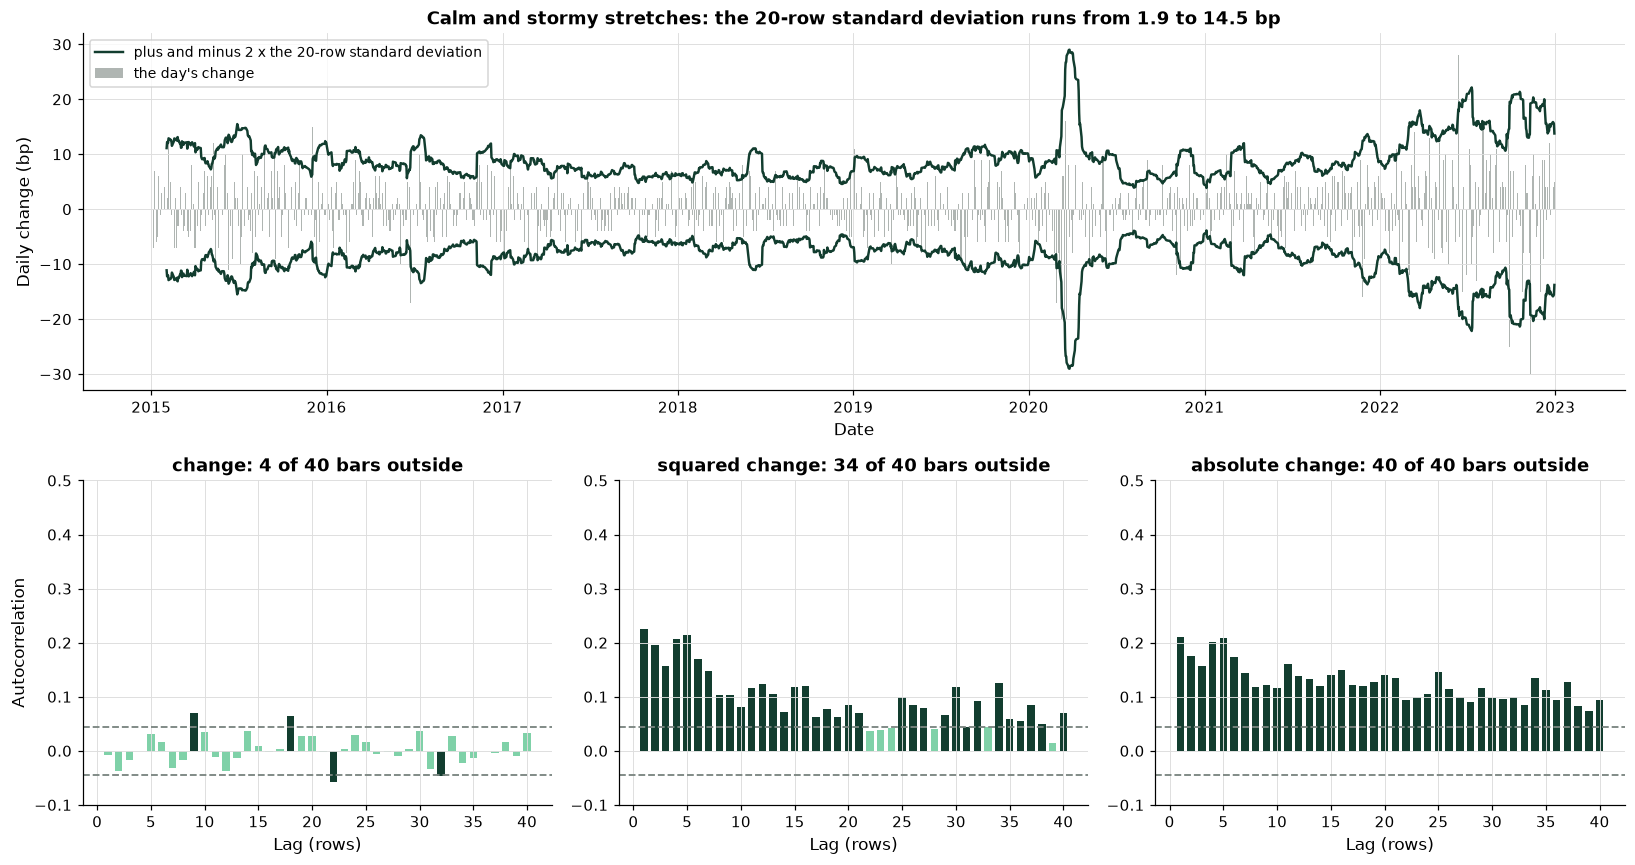

In [12]:
# top: the 10 Yr's daily change and the 20-row standard deviation, both signs; bottom: the autocorrelation of the change, its square, and its absolute value
fig = plt.figure(figsize=(15, 8))
grid = fig.add_gridspec(2, 3, height_ratios=[1.1, 1])
top = fig.add_subplot(grid[0, :])
top.bar(ten.index, ten, color=plotkit.GREY, width=1.0, alpha=0.6, label="the day's change")
top.plot(rolling_sd.index, 2 * rolling_sd, color=plotkit.GREEN_DARK, linewidth=1.6, label="plus and minus 2 x the 20-row standard deviation")
top.plot(rolling_sd.index, -2 * rolling_sd, color=plotkit.GREEN_DARK, linewidth=1.6)
top.set_xlabel("Date")
top.set_ylabel("Daily change (bp)")
top.set_title(f"Calm and stormy stretches: the 20-row standard deviation runs from {rolling_sd.min():.1f} to {rolling_sd.max():.1f} bp")
top.legend(loc="upper left", fontsize=9)
lags_axis = np.arange(1, 41)
for number, (label, values_acf) in enumerate(acfs.items()):
    ax = fig.add_subplot(grid[1, number])
    ax.bar(lags_axis, values_acf[1:], color=[plotkit.GREEN_DARK if abs(v) > band else plotkit.GREEN_LIGHT for v in values_acf[1:]], width=0.7)
    ax.axhline(band, color=plotkit.GREY, linestyle="--", linewidth=1.2)
    ax.axhline(-band, color=plotkit.GREY, linestyle="--", linewidth=1.2)
    ax.set_xlabel("Lag (rows)")
    ax.set_title(f"{label}: {int((np.abs(values_acf[1:]) > band).sum())} of 40 bars outside")
    ax.set_ylim(-0.1, 0.5)
fig.axes[1].set_ylabel("Autocorrelation")
fig.tight_layout()
plt.show()

* **Top:** the green lines are two standard deviations of the last 20 changes, a moving envelope. It swells to 14.5 bp (the 20-row standard deviation) on 2020-03-26 and shrinks to 1.9 on 2021-01-05: a ratio of 7.5. A model with a constant size would draw a flat envelope.
* **Bottom:** the change has 4 of 40 bars outside the band, and a lag-1 autocorrelation of -0.007. Its square has 34 of 40 outside, with a lag-1 value of 0.225, and its absolute value 40 of 40, with 0.211. The dark bars are outside the band.
* The Ljung-Box p-values for the squares are below one in a million on all three series, which is day 4's result for the 10 Yr, now also for the 2s10s slope and the invented IG spread. **The memory is in the size.**

## 7.2 GARCH(1,1)

**How it works.** A GARCH(1,1) says that the day's change is the average change **mu** plus a shock, and that the *size* of the shock has its own recursion. The variance for a day equals a constant **omega**, plus **alpha** times the squared shock of the day before, plus **beta** times the variance of the day before. A big shock raises the next row's variance by alpha times its square, and that raise then fades by the factor beta each row. The model is fitted by **maximum likelihood**: the optimiser looks for the four numbers that make the changes the most probable given the variances they imply. You control the orders (1 and 1 here) and the shape of the shock; what comes out is the four coefficients, a variance for every row (the conditional volatility is its square root), and the **persistence** alpha + beta, which is the share of a variance gap still there one row later. Its **half-life** is the number of rows until half of a shock's effect has faded.

Q. Write `garch_half_life`, and its first test. Read the docstring first.

In [13]:
%%writefile -a tskit.py


from arch import arch_model

ABS_SCALE = float(np.sqrt(2 / np.pi))   # for a normal shock with standard deviation s, the average absolute shock is s x ABS_SCALE


def garch_half_life(alpha: float, beta: float) -> float:
    """The number of rows after which half of a volatility shock has faded, from a GARCH(1,1)'s alpha and beta.

    Inputs: alpha, the weight on the latest squared shock; beta, the weight on the variance before. Their sum is the
    persistence: the share of a variance gap that is still there one row later.
    Output: ln(0.5) / ln(alpha + beta) rows. At a persistence of 0.9 it is 6.6 rows; at 0.99 it is 69.
    Raises ValueError unless 0 < alpha + beta < 1: at 1 or above a shock never fades and the half-life does not exist.
    """
    persistence = alpha + beta
    if not 0 < persistence < 1:
        raise ValueError(f"alpha + beta must be above 0 and below 1 for a half-life; got {persistence:.4f}")
    return float(np.log(0.5) / np.log(persistence))

Appending to tskit.py


* It is one line of algebra: the share left after k rows is persistence to the power k, which is one half at k = ln(0.5) / ln(persistence). In Excel it is `=LN(0.5)/LN(F3+F4)`.
* It refuses a persistence of 1 or more, because a shock that never fades has no half-life. That refusal comes up again with the 2 Yr in the exercises.

Q. Write its test: a persistence of 0.9, and the refusals.

In [14]:
%%writefile -a test_tskit.py


def garch_series(rows: int = 1500) -> pd.Series:
    """A seeded GARCH(1,1) of daily changes in bp: omega 0.1, alpha 0.1, beta 0.85, on business days."""
    rng = np.random.default_rng(11)
    shocks = rng.standard_normal(rows)
    variance = np.empty(rows)
    values = np.empty(rows)
    variance[0] = 0.1 / (1 - 0.95)
    values[0] = np.sqrt(variance[0]) * shocks[0]
    for row in range(1, rows):
        variance[row] = 0.1 + 0.1 * values[row - 1] ** 2 + 0.85 * variance[row - 1]
        values[row] = np.sqrt(variance[row]) * shocks[row]
    return pd.Series(values, index=pd.bdate_range("2020-01-01", periods=rows))


def test_garch_half_life_and_refusals():
    assert tskit.garch_half_life(0.05, 0.85) == pytest.approx(np.log(0.5) / np.log(0.9))
    # after that many rows, 0.9 to that power is one half
    assert 0.9 ** tskit.garch_half_life(0.05, 0.85) == pytest.approx(0.5)
    for alpha, beta in ((0.1, 0.9), (0.2, 0.9), (0.0, 0.0), (-0.2, 0.1)):
        with pytest.raises(ValueError, match="above 0 and below 1"):
            tskit.garch_half_life(alpha, beta)

Appending to test_tskit.py


Q. Reload the modules and run the tests.

In [15]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print(f"garch_half_life in tskit: {hasattr(tskit, 'garch_half_life')}")

garch_half_life in tskit: True


In [16]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...................................                                      [100%]
35 passed in 6.14s



* `35 passed`: day 6's 34 and one new one. The file also holds `ABS_SCALE`, the constant section 7.5 uses.

Q. Add `fit_garch`, the one function the course fits GARCH models through, and `garch_variance`, the recursion written out.

In [17]:
%%writefile -a tskit.py


def fit_garch(changes, mean: str = "Constant", vol: str = "GARCH", p: int = 1, o: int = 0, q: int = 1,
              dist: str = "normal", **settings):
    """Fit a GARCH-family model by maximum likelihood to a plain array of changes and return arch's results.

    Inputs: changes, a one-dimensional array of at least 100 daily changes in bp with no blank (a change, never a level);
    mean, vol, p, o, q, dist, as for arch_model ("Constant" or "Zero" mean; "GARCH", "EGARCH", ...; lags of the squared
    shock, the asymmetry term, and the variance; "normal", "t", "skewt", "ged"); settings, any other arch_model setting.
    Output: the fitted results. For a GARCH(1,1), results.params is mu, omega, alpha[1], beta[1] (then nu for "t").
    The data are not rescaled (changes in bp are of the size arch expects), the optimiser's progress is not printed,
    and the fit raises if the optimiser did not converge.
    Raises ValueError for fewer than 100 values or a blank, and RuntimeError when the optimiser did not converge.
    """
    array = np.asarray(changes, dtype=float)
    if array.ndim != 1 or len(array) < 100 or np.isnan(array).any():
        raise ValueError("changes must be a one-dimensional array of at least 100 numbers with no blank")
    model = arch_model(array, mean=mean, vol=vol, p=p, o=o, q=q, dist=dist, rescale=False, **settings)
    results = model.fit(disp="off", update_freq=0)
    if results.convergence_flag != 0:
        raise RuntimeError(f"{vol}({p}, {o}, {q}) with a {dist} shock did not converge on {len(array)} values")
    return results


def garch_variance(changes, mu: float, omega: float, alpha: float, beta: float, variance0: float) -> np.ndarray:
    """The one-step variance of a GARCH(1,1) for every row, by the recursion, from fixed coefficients.

    Inputs: changes, a one-dimensional array in bp (a NaN stops the recursion from the next row on); mu, omega, alpha, and
    beta, the model's mean and variance coefficients; variance0, the variance for the first row.
    Output: an array the length of changes. Entry 0 is variance0, and entry t is
    omega + alpha (changes[t-1] - mu)^2 + beta x entry t-1: the variance for row t uses only the rows before it.
    """
    array = np.asarray(changes, dtype=float)
    out = np.empty(len(array))
    out[0] = variance0
    for row in range(1, len(array)):
        out[row] = omega + alpha * (array[row - 1] - mu) ** 2 + beta * out[row - 1]
    return out

Appending to tskit.py


* `fit_garch` takes a plain array of **changes**. It does not rescale the data (changes in bp are of the size `arch` likes), prints nothing, and raises if the optimiser did not converge, as `fit_arima` does.
* `garch_variance` is the recursion with fixed coefficients. It is what Excel does, and what section 7.5 needs: given the fitted coefficients and the variance of the last training row, it runs the recursion on through the test rows, where each variance uses only the rows before it.

Q. Write the tests: the fit recovers the persistence of a seeded GARCH, and the recursion equals the conditional variance `arch` returns.

In [18]:
%%writefile -a test_tskit.py


def test_fit_garch_recovers_a_garch():
    results = tskit.fit_garch(garch_series().to_numpy())
    mu, omega, alpha, beta = results.params
    # 1,500 seeded values: the persistence is near the 0.95 that made them
    assert alpha + beta == pytest.approx(0.95, abs=0.04) and alpha == pytest.approx(0.1, abs=0.05)
    assert results.convergence_flag == 0


def test_garch_variance_equals_arch_conditional_variance():
    values = garch_series().to_numpy()
    results = tskit.fit_garch(values)
    mu, omega, alpha, beta = results.params
    again = tskit.garch_variance(values, mu, omega, alpha, beta, results.conditional_volatility[0] ** 2)
    assert again == pytest.approx(results.conditional_volatility ** 2, rel=1e-8)

Appending to test_tskit.py


Q. Reload the modules and run the tests.

In [19]:
# the files changed, so reload before using the new functions
importlib.reload(tskit)
print(f"fit_garch and garch_variance in tskit: {hasattr(tskit, 'fit_garch') and hasattr(tskit, 'garch_variance')}")

fit_garch and garch_variance in tskit: True


In [20]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.....................................                                    [100%]
37 passed in 6.59s



* `37 passed`.

Q. Fit a GARCH(1,1) to the 10 Yr's development changes, read every coefficient, and check the recursion by hand.

In [21]:
# a GARCH(1,1) on all 2,000 development changes of the 10 Yr: a description of these years (the scores in section 7.5 refit fold by fold)
values_ten = changes["10 Yr"].to_numpy()
garch = tskit.fit_garch(values_ten)
mu, omega, alpha, beta = (float(v) for v in np.asarray(garch.params))
persistence = alpha + beta
half_life = tskit.garch_half_life(alpha, beta)
long_run_vol = float(np.sqrt(omega / (1 - persistence)))
garch_vol = pd.Series(garch.conditional_volatility, index=changes.index)

# the recursion by hand, started from arch's first variance, gives arch's variance on every row
by_hand = tskit.garch_variance(values_ten, mu, omega, alpha, beta, garch.conditional_volatility[0] ** 2)
print(f"the recursion equals arch's conditional variance on all {len(by_hand):,} rows within 1e-8 (relative): {bool(np.allclose(by_hand, garch.conditional_volatility ** 2, rtol=1e-8))}")

# the optimiser's last digits can move with the machine, so the table shows 3 decimals (2 for the half-life and the volatilities)
garch_table = pd.DataFrame({
    "value": [round(v, 3) for v in (mu, omega, alpha, beta, persistence)] + [round(half_life, 2), round(long_run_vol, 2), round(changes["10 Yr"].std(), 2)],
    "standard error": [round(float(v), 3) for v in garch.std_err[:4]] + [np.nan] * 4,
}, index=pd.Index(["mu, the average change (bp)", "omega, the constant (bp squared)", "alpha, the weight on the latest squared shock", "beta, the weight on the variance before",
                   "persistence, alpha + beta", "half-life of a shock (rows)", "long-run volatility, sqrt(omega / (1 - alpha - beta)) (bp)",
                   "the sample standard deviation (bp)"], name="Quantity"))
print(garch_table.to_string())

# the coefficients as a student pastes them into Excel: rounded to 3 decimals, with the sample variance of all the changes as the first variance
pasted = {"mu": round(mu, 3), "omega": round(omega, 3), "alpha": round(alpha, 3), "beta": round(beta, 3), "variance0": round(float(changes["10 Yr"].var()), 3)}
pasted_vol = np.sqrt(tskit.garch_variance(values_ten, pasted["mu"], pasted["omega"], pasted["alpha"], pasted["beta"], pasted["variance0"]))
gap_vol = np.abs(pasted_vol - garch.conditional_volatility)
print(f"with the pasted numbers the volatility is within {gap_vol.max():.1f} bp of arch's on all {len(pasted_vol):,} rows, and within {gap_vol[200:].max():.1f} bp after the first 200")

plotkit.styled(garch_table, [], "A GARCH(1,1) fitted to the 10 Yr's 2,000 development changes: coefficients and what they imply", fmt="{:.3f}")

the recursion equals arch's conditional variance on all 2,000 rows within 1e-8 (relative): True
                                                             value  standard error
Quantity                                                                          
mu, the average change (bp)                                  0.071           0.093
omega, the constant (bp squared)                             0.467           0.242
alpha, the weight on the latest squared shock                0.066           0.017
beta, the weight on the variance before                      0.915           0.025
persistence, alpha + beta                                    0.981             NaN
half-life of a shock (rows)                                 35.950             NaN
long-run volatility, sqrt(omega / (1 - alpha - beta)) (bp)   4.940             NaN
the sample standard deviation (bp)                           5.030             NaN
with the pasted numbers the volatility is within 0.9 bp of arch's on all 2

,value,standard error
Quantity,,
"mu, the average change (bp)",0.071,0.093
"omega, the constant (bp squared)",0.467,0.242
"alpha, the weight on the latest squared shock",0.066,0.017
"beta, the weight on the variance before",0.915,0.025
"persistence, alpha + beta",0.981,
half-life of a shock (rows),35.950,
"long-run volatility, sqrt(omega / (1 - alpha - beta)) (bp)",4.940,
the sample standard deviation (bp),5.030,


* **alpha is 0.066 and beta 0.915**: a squared shock moves the next variance by about 6.6 percent of its size, and 91.5 percent of the old variance carries on. Their sum, the persistence, is **0.981**: the half-life of a shock is **35.9 rows**.
* The long-run volatility, where the recursion would settle if no shock disturbed it, is 4.94 bp, against a sample standard deviation of 5.03 bp: close: the fit makes the long-run variance match the sample's.
* The recursion written by hand equals `arch`'s variance on all 2,000 rows to 1e-8: GARCH is not a black box, it is one line repeated.

Q. Simulate four GARCH(1,1)s from the same shocks, with the same long-run volatility, and change only alpha and beta.

In [22]:
# the same 1,000 shocks through four GARCH(1,1)s with the same long-run volatility of 2 bp: only alpha and beta change
rng = np.random.default_rng(SEED)
shocks = rng.standard_normal(1_000)
settings = [("no clustering", 0.0, 0.0), ("quick and short: alpha 0.20, beta 0.70", 0.20, 0.70),
            ("alpha 0.05, beta 0.90", 0.05, 0.90), ("slow and long: alpha 0.05, beta 0.94", 0.05, 0.94)]
sim = {}
for label, a, b in settings:
    persistence_sim = a + b
    variance = np.empty(1_000)
    series = np.empty(1_000)
    variance[0] = 4.0
    for row in range(1_000):
        if row:
            variance[row] = 4.0 * (1 - persistence_sim) + a * series[row - 1] ** 2 + b * variance[row - 1]
        series[row] = np.sqrt(variance[row]) * shocks[row]
    sim[label] = (series, np.sqrt(variance), persistence_sim, tskit.garch_half_life(a, b) if persistence_sim > 0 else 0.0)
sim_table = pd.DataFrame({
    "alpha": [a for _, a, _ in settings], "beta": [b for _, _, b in settings],
    "persistence": [a + b for _, a, b in settings],
    "half-life (rows)": [tskit.garch_half_life(a, b) if a + b > 0 else 0.0 for _, a, b in settings],
    "highest volatility (bp)": [sim[label][1].max() for label, _, _ in settings],
}, index=pd.Index([label for label, _, _ in settings], name="setting"))
print(sim_table.round(3).to_string())

plotkit.styled(sim_table, [], "Four simulated GARCH(1,1)s from the same 1,000 shocks: alpha and beta, persistence, half-life, and the highest volatility", fmt="{:.3f}")

                                        alpha  beta  persistence  half-life (rows)  highest volatility (bp)
setting                                                                                                    
no clustering                            0.00  0.00         0.00             0.000                    2.000
quick and short: alpha 0.20, beta 0.70   0.20  0.70         0.90             6.579                    5.620
alpha 0.05, beta 0.90                    0.05  0.90         0.95            13.513                    2.810
slow and long: alpha 0.05, beta 0.94     0.05  0.94         0.99            68.968                    2.459


,alpha,beta,persistence,half-life (rows),highest volatility (bp)
setting,,,,,
no clustering,0.000,0.000,0.000,0.000,2.000
"quick and short: alpha 0.20, beta 0.70",0.200,0.700,0.900,6.579,5.620
"alpha 0.05, beta 0.90",0.050,0.900,0.950,13.513,2.810
"slow and long: alpha 0.05, beta 0.94",0.050,0.940,0.990,68.968,2.459


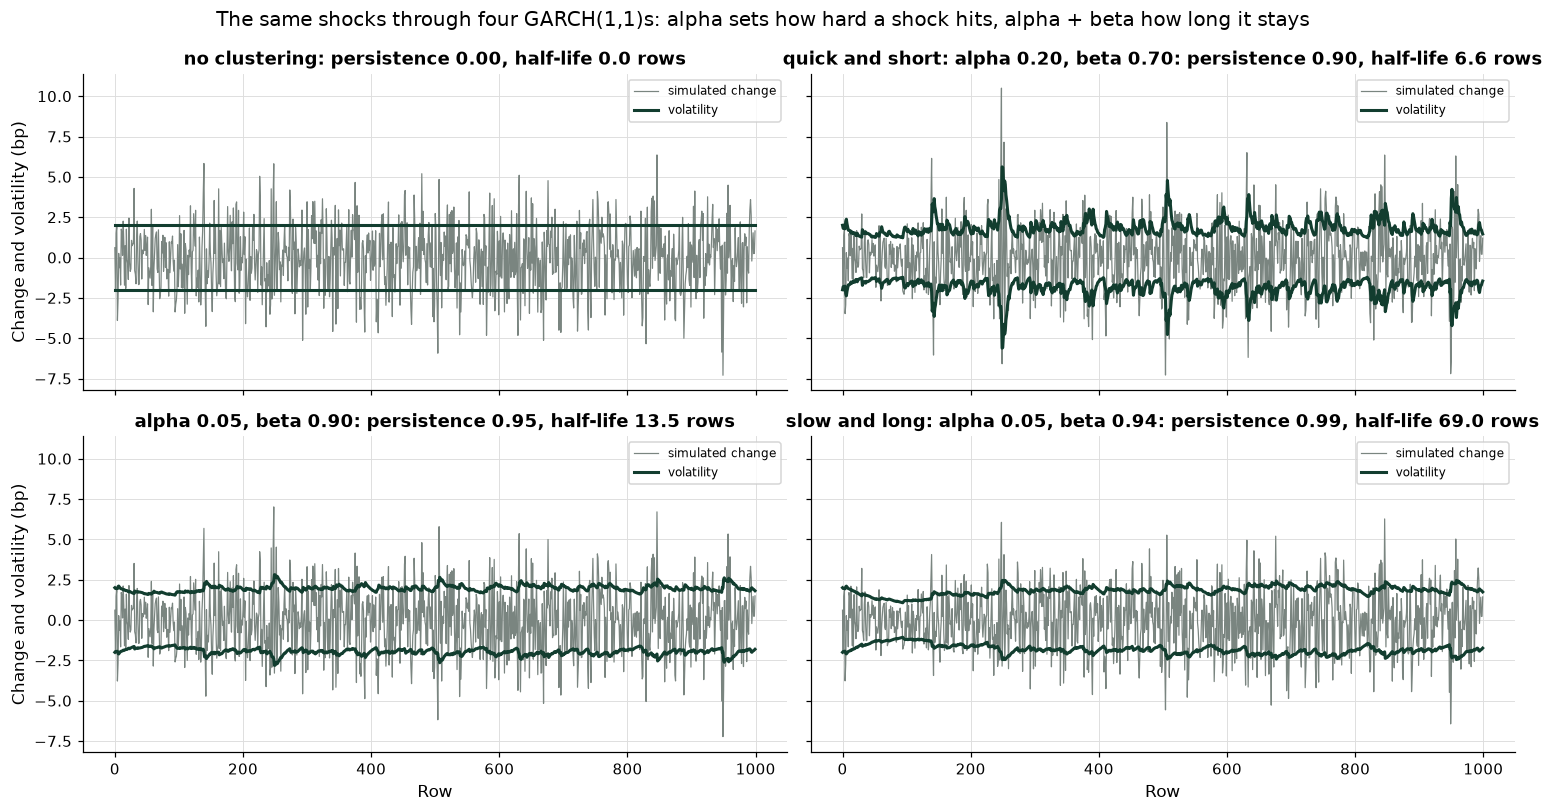

In [23]:
# one set of shocks, four GARCH(1,1)s with the same long-run volatility: the simulated change in grey, the model's volatility in green
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True, sharey=True)
for ax, (label, (series_sim, vol_sim, persistence_sim, half)) in zip(axes.ravel(), sim.items()):
    ax.plot(series_sim, color=plotkit.GREY, linewidth=0.8, label="simulated change")
    ax.plot(vol_sim, color=plotkit.GREEN_DARK, linewidth=2, label="volatility")
    ax.plot(-vol_sim, color=plotkit.GREEN_DARK, linewidth=2)
    ax.set_title(f"{label}: persistence {persistence_sim:.2f}, half-life {half:.1f} rows")
    ax.legend(loc="upper right", fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Row")
for ax in axes[:, 0]:
    ax.set_ylabel("Change and volatility (bp)")
fig.suptitle("The same shocks through four GARCH(1,1)s: alpha sets how hard a shock hits, alpha + beta how long it stays")
fig.tight_layout()
plt.show()

* How to read it: grey is the simulated change and green is the volatility the model sets for each row, drawn both signs. With no clustering (alpha and beta 0) the envelope is flat. With a high alpha the envelope jumps after every large move and falls back fast (6.6-row half-life). With a persistence of 0.99 the envelope moves slowly and stays high or low for months (69-row half-life). **Alpha sets how hard a shock hits; alpha + beta sets how long it stays.** The 10 Yr's fit, alpha 0.07 and beta 0.92, sits between the third and fourth panels.

Q. Draw how fast a variance shock fades for four persistences, with the 10 Yr's fit among them.

In [24]:
# a one-off shock lifts the variance by a gap; each row a share (persistence) of the gap is left, so the gap after k rows is persistence to the power k
decay_rows = np.arange(0, 121)
decay_cases = {"persistence 0.90": 0.90, "persistence 0.95": 0.95, f"the 10 Yr's fit, {persistence:.3f}": persistence, "persistence 0.99": 0.99}
decay = pd.DataFrame({label: p ** decay_rows for label, p in decay_cases.items()}, index=pd.Index(decay_rows, name="rows after the shock"))
decay_half = pd.Series({label: np.log(0.5) / np.log(p) for label, p in decay_cases.items()}, name="half-life (rows)")
print(decay_half.round(1).to_string())

persistence 0.90           6.6
persistence 0.95          13.5
the 10 Yr's fit, 0.981    35.9
persistence 0.99          69.0


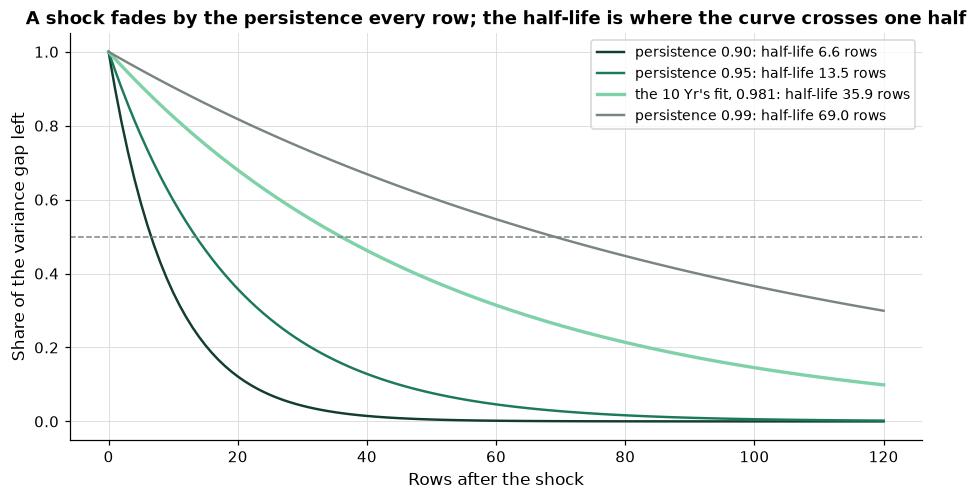

In [25]:
# the share of a variance gap left after a one-off shock, for four persistences; the half-life of each is where its curve crosses 0.5
fig, ax = plt.subplots(figsize=(10, 4.8))
for label in decay.columns:
    ax.plot(decay.index, decay[label], linewidth=2.2 if "10 Yr" in label else 1.6, label=f"{label}: half-life {decay_half[label]:.1f} rows")
ax.axhline(0.5, color=plotkit.GREY, linestyle="--", linewidth=1)
ax.set_xlabel("Rows after the shock")
ax.set_ylabel("Share of the variance gap left")
ax.set_title("A shock fades by the persistence every row; the half-life is where the curve crosses one half")
ax.legend(loc="upper right", fontsize=9)
plt.show()

* Each curve is persistence to the power k. A persistence of 0.90 halves in 6.6 rows, 0.95 in 13.5, the 10 Yr's fit in 35.9, and 0.99 in 69. A small change in persistence makes a large change in memory: this is why persistence is the number to read first.

## 7.3 Rolling, EWMA, and GARCH Volatility

Q. Put the three volatility measures of the 10 Yr's change on one chart: the 20-row standard deviation, day 6's RiskMetrics EWMA, and the GARCH(1,1).

In [26]:
# three volatility measures of the 10 Yr's change on every date: a 20-row standard deviation, RiskMetrics' EWMA (day 6), and the GARCH(1,1)
vol_three = pd.DataFrame({"20-row rolling": rolling_sd, "EWMA, lambda 0.94": np.sqrt(tskit.ewma(ten ** 2, 0.06)), "GARCH(1,1)": garch_vol})
vol_corr = vol_three.corr()
print(vol_three.describe().loc[["mean", "min", "max"]].round(2).to_string())
print(f"correlation of the GARCH volatility with the EWMA: {vol_corr.loc['GARCH(1,1)', 'EWMA, lambda 0.94']:.3f}, with the rolling value: {vol_corr.loc['GARCH(1,1)', '20-row rolling']:.3f}")

plotkit.styled(vol_corr, [], "Correlation of the three volatility measures of the 10 Yr's daily change, development years", fmt="{:.3f}")

      20-row rolling  EWMA, lambda 0.94  GARCH(1,1)
mean            4.65               4.73        4.80
min             1.93               2.33        3.00
max            14.51              13.14       12.94
correlation of the GARCH volatility with the EWMA: 0.979, with the rolling value: 0.961


,20-row rolling,"EWMA, lambda 0.94","GARCH(1,1)"
20-row rolling,1.000,0.959,0.961
"EWMA, lambda 0.94",0.959,1.000,0.979
"GARCH(1,1)",0.961,0.979,1.000


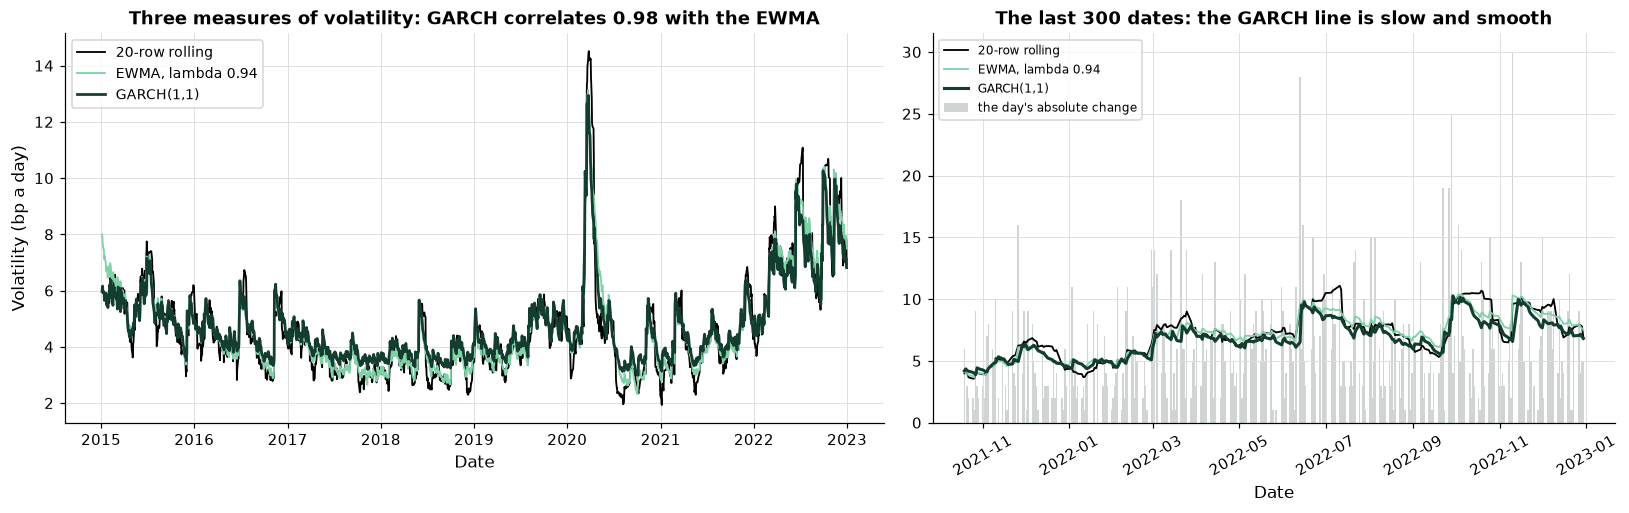

In [27]:
# left: three volatility measures over the development years; right: the last 300 dates with the size of each change behind them
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
colors = {"20-row rolling": "black", "EWMA, lambda 0.94": plotkit.GREEN_LIGHT, "GARCH(1,1)": plotkit.GREEN_DARK}
for column in vol_three.columns:
    left.plot(vol_three.index, vol_three[column], color=colors[column], linewidth=1.2 if column != "GARCH(1,1)" else 1.8, label=column)
left.set_xlabel("Date")
left.set_ylabel("Volatility (bp a day)")
left.set_title(f"Three measures of volatility: GARCH correlates {vol_corr.loc['GARCH(1,1)', 'EWMA, lambda 0.94']:.2f} with the EWMA")
left.legend(loc="upper left", fontsize=9)
shown = vol_three.iloc[-300:]
right.bar(shown.index, ten.abs().iloc[-300:], color=plotkit.GREY, alpha=0.35, width=1.0, label="the day's absolute change")
for column in vol_three.columns:
    right.plot(shown.index, shown[column], color=colors[column], linewidth=1.2 if column != "GARCH(1,1)" else 2, label=column)
right.set_xlabel("Date")
right.set_title("The last 300 dates: the GARCH line is slow and smooth")
right.tick_params(axis="x", rotation=30)
right.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

* All three rise and fall together: the GARCH volatility correlates 0.979 with the EWMA and 0.961 with the rolling value. The EWMA is a GARCH(1,1) with omega set to 0 and alpha + beta set to 1, so the two agree closely. Its beta of 0.92 keeps the old variance in the average, and it pulls toward the long-run level between storms, which the EWMA has no level to do.
* This is a description of the development years: the GARCH here uses coefficients fitted on all of them. Section 7.5 refits fold by fold.

## 7.4 Every Setting of `arch_model`

Q. Read every setting of `arch_model` and of its `fit`, with the defaults taken from the installed `arch`.

In [28]:
import inspect

from arch import arch_model
from arch.univariate.mean import HARX

model_defaults = {name: p.default for name, p in inspect.signature(arch_model).parameters.items()}
fit_defaults = {name: p.default for name, p in inspect.signature(HARX.fit).parameters.items()}
rows = [
    ("mean", model_defaults["mean"], "the model of the average change: Constant, Zero, LS, AR, HAR", "Zero fixes the average at 0 bp; Constant fits mu", "no"),
    ("lags", model_defaults["lags"], "autoregressive lags in the mean (an AR, ARX, or HAR mean)", "day 5 found no memory in the change itself, so 0", "no"),
    ("vol", model_defaults["vol"], "the variance model: GARCH, ARCH, EGARCH, FIGARCH, APARCH, HARCH", "EGARCH models the log of the variance and lets a fall and a rise count differently", "yes"),
    ("p", model_defaults["p"], "lags of the squared shock (the ARCH part)", "more lags let older shocks count separately; alpha becomes a list", "yes"),
    ("o", model_defaults["o"], "lags of an asymmetry term: a shock of one sign counts more (GJR)", "1 adds a weight on squared shocks below zero", "yes"),
    ("q", model_defaults["q"], "lags of the variance (the GARCH part)", "more lags let older variances count separately", "yes"),
    ("power", model_defaults["power"], "the power of the shock in the recursion: 2 is a variance", "1 models the absolute shock (an APARCH idea)", "no"),
    ("dist", model_defaults["dist"], "the distribution of the standardized shock: normal, t, skewt, ged", "t adds a degrees-of-freedom number and heavier tails", "yes"),
    ("hold_back", model_defaults["hold_back"], "rows at the start left out of the likelihood", "only matters with lags in the mean", "no"),
    ("rescale", model_defaults["rescale"], "whether arch rescales the data to a size it likes (None means it may)", "tskit passes False: changes in bp are already the right size", "no"),
    ("update_freq, disp (fit)", fit_defaults["update_freq"], "how often the optimiser prints its progress", "tskit prints nothing", "no"),
    ("cov_type (fit)", fit_defaults["cov_type"], "how standard errors are computed: robust or classic", "robust does not rely on the shocks being normal", "no"),
    ("starting_values, tol, options, backcast (fit)", fit_defaults["backcast"], "the optimiser's start, tolerance, and the first variance", "None uses arch's own backcast: a weighted average of the first squared shocks", "no"),
]
settings_table = pd.DataFrame(rows, columns=["setting", "default", "what it controls", "raising it or turning it on", "tune first"]).set_index("setting")
settings_table["default"] = settings_table["default"].map(repr)

plotkit.styled(settings_table, [], "Every setting of arch_model: the defaults read from the installed arch")

,default,what it controls,raising it or turning it on,tune first
setting,,,,
mean,'Constant',"the model of the average change: Constant, Zero, LS, AR, HAR",Zero fixes the average at 0 bp; Constant fits mu,no
lags,0,"autoregressive lags in the mean (an AR, ARX, or HAR mean)","day 5 found no memory in the change itself, so 0",no
vol,'GARCH',"the variance model: GARCH, ARCH, EGARCH, FIGARCH, APARCH, HARCH",EGARCH models the log of the variance and lets a fall and a rise count differently,yes
p,1,lags of the squared shock (the ARCH part),more lags let older shocks count separately; alpha becomes a list,yes
o,0,lags of an asymmetry term: a shock of one sign counts more (GJR),1 adds a weight on squared shocks below zero,yes
q,1,lags of the variance (the GARCH part),more lags let older variances count separately,yes
power,2.0,the power of the shock in the recursion: 2 is a variance,1 models the absolute shock (an APARCH idea),no
dist,'normal',"the distribution of the standardized shock: normal, t, skewt, ged",t adds a degrees-of-freedom number and heavier tails,yes
hold_back,None,rows at the start left out of the likelihood,only matters with lags in the mean,no


* Five settings matter, marked "tune first": `vol`, `p`, `o`, `q`, and `dist`. The mean, the lags, and the optimiser's settings are left at what the course uses.

Q. Sweep the shock's distribution: normal, Student's t, skewed t, and the generalised error.

In [29]:
from scipy import stats

# the shock's distribution: normal, t, skewed t, and the generalised error, on all 2,000 changes
dist_rows = []
dist_fits = {}
for dist in ["normal", "t", "skewt", "ged"]:
    fit = tskit.fit_garch(values_ten, dist=dist)
    dist_fits[dist] = fit
    shape = round(float(fit.params["nu"]), 2) if "nu" in fit.params.index else np.nan
    dist_rows.append({"dist": dist, "log-likelihood": fit.loglikelihood, "AIC": fit.aic, "BIC": fit.bic, "shape nu": shape,
                      "alpha": fit.params["alpha[1]"], "beta": fit.params["beta[1]"],
                      "excess kurtosis of the standardized residuals": stats.kurtosis(fit.std_resid)})
dist_table = pd.DataFrame(dist_rows).set_index("dist")
print(dist_table.round(2).to_string())

plotkit.styled(dist_table, ["AIC", "BIC"], "A GARCH(1,1) by the distribution of the shock, all 2,000 development changes", higher_is_better=False, fmt="{:.3f}")

        log-likelihood       AIC       BIC  shape nu  alpha  beta  excess kurtosis of the standardized residuals
dist                                                                                                            
normal        -5904.08  11816.15  11838.56       NaN   0.07  0.92                                           1.17
t             -5884.50  11779.00  11807.00     11.16   0.06  0.92                                           1.18
skewt         -5884.21  11780.43  11814.03       NaN   0.06  0.92                                           1.18
ged           -5892.95  11795.90  11823.91      1.64   0.06  0.92                                           1.17


,log-likelihood,AIC,BIC,shape nu,alpha,beta,excess kurtosis of the standardized residuals
dist,,,,,,,
normal,-5904.076,11816.151,11838.555,,0.066,0.915,1.169
t,-5884.500,11779.000,11807.004,11.160,0.062,0.922,1.180
skewt,-5884.213,11780.425,11814.030,,0.063,0.921,1.181
ged,-5892.951,11795.901,11823.906,1.640,0.064,0.918,1.172


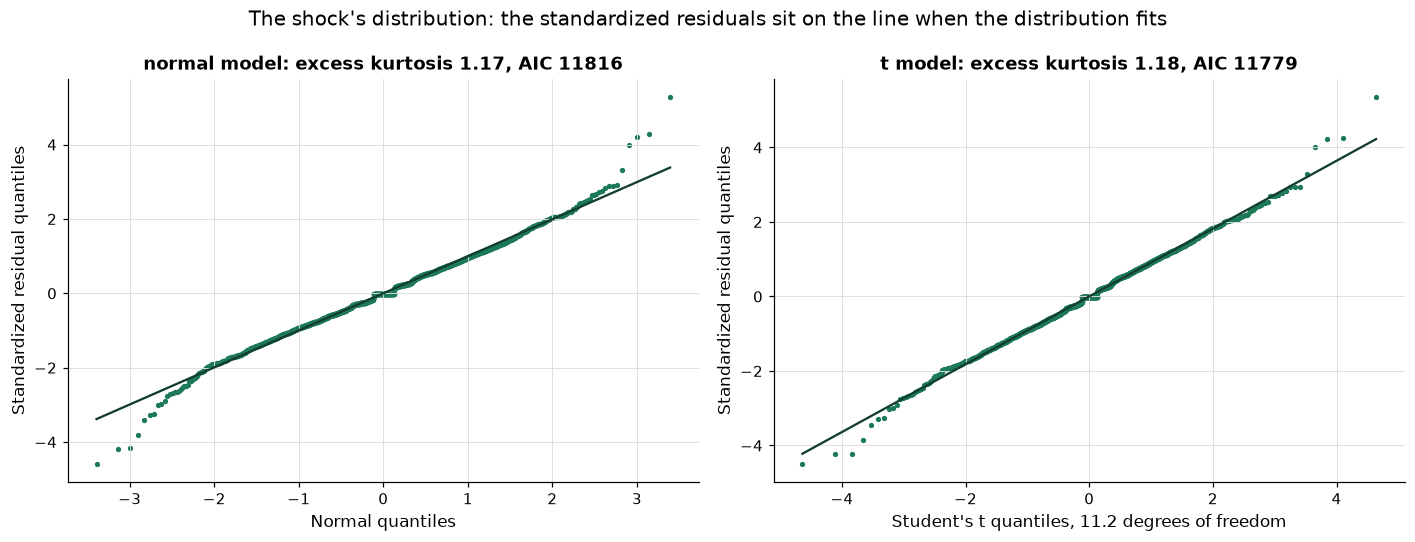

In [30]:
# Q-Q plots of the standardized residuals: against a normal for the normal model, against a Student's t for the t model
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))
nu_t = float(dist_fits["t"].params["nu"])
for ax, dist in zip((left, right), ("normal", "t")):
    resid = np.asarray(dist_fits[dist].std_resid)
    resid = resid[~np.isnan(resid)]
    if dist == "normal":
        (theory, ordered), (slope_q, intercept_q, _) = stats.probplot(resid, dist="norm")
        ax.set_xlabel("Normal quantiles")
    else:
        (theory, ordered), (slope_q, intercept_q, _) = stats.probplot(resid, dist=stats.t, sparams=(nu_t,))
        ax.set_xlabel(f"Student's t quantiles, {nu_t:.1f} degrees of freedom")
    ax.scatter(theory, ordered, s=6, color=plotkit.GREEN)
    ax.plot(theory, slope_q * theory + intercept_q, color=plotkit.GREEN_DARK, linewidth=1.5)
    ax.set_ylabel("Standardized residual quantiles")
    ax.set_title(f"{dist} model: excess kurtosis {stats.kurtosis(resid):.2f}, AIC {dist_table.loc[dist, 'AIC']:.0f}")
fig.suptitle("The shock's distribution: the standardized residuals sit on the line when the distribution fits")
fig.tight_layout()
plt.show()

* **Normal against t.** The normal model's standardized residuals have an excess kurtosis of 1.17, and the Q-Q plot on the left bends away from the line in both tails: the shocks are heavier-tailed than a normal's. The t model adds one number, the degrees of freedom, 11.2, and its AIC falls from 11816 to 11779. The lowest BIC is the t model's. The skewed t and the generalised error do not improve on it. A t with about 11 degrees of freedom has tails fat enough for a bond market's worst days; as the degrees of freedom grow it turns into the normal.
* Alpha and beta barely move between the distributions (the table's columns): the clustering is the same, and only the shape of the tails changes. Which tails matter depends on what the volatility is for: the **size** score below is not much affected, and a model that must say how likely a very large move is cares a lot.

Q. Sweep the variance model: ARCH(1), GARCH(1,1), GJR-GARCH, EGARCH, and GARCH(2,1).

In [31]:
# the variance model: five choices on the same 2,000 changes, normal shocks
variants = {"ARCH(1)": dict(vol="ARCH", p=1, q=0), "GARCH(1,1)": dict(vol="GARCH", p=1, q=1), "GJR-GARCH(1,1,1)": dict(vol="GARCH", p=1, o=1, q=1),
            "EGARCH(1,1)": dict(vol="EGARCH", p=1, q=1), "GARCH(2,1)": dict(vol="GARCH", p=2, q=1)}
variant_rows = []
for label, settings in variants.items():
    fit = tskit.fit_garch(values_ten, **settings)
    variant_rows.append({"model": label, "parameters": len(fit.params), "log-likelihood": fit.loglikelihood, "AIC": fit.aic, "BIC": fit.bic})
variant_table = pd.DataFrame(variant_rows).set_index("model")
print(variant_table.round(2).to_string())

plotkit.styled(variant_table, ["AIC", "BIC"], "Five variance models on the 10 Yr's 2,000 development changes, normal shocks", higher_is_better=False, fmt="{:.2f}")

                  parameters  log-likelihood       AIC       BIC
model                                                           
ARCH(1)                    3        -6006.43  12018.85  12035.66
GARCH(1,1)                 4        -5904.08  11816.15  11838.56
GJR-GARCH(1,1,1)           5        -5904.05  11818.11  11846.11
EGARCH(1,1)                4        -5905.45  11818.90  11841.30
GARCH(2,1)                 5        -5904.08  11818.15  11846.16


,parameters,log-likelihood,AIC,BIC
model,,,,
ARCH(1),3,-6006.43,12018.85,12035.66
"GARCH(1,1)",4,-5904.08,11816.15,11838.56
"GJR-GARCH(1,1,1)",5,-5904.05,11818.11,11846.11
"EGARCH(1,1)",4,-5905.45,11818.90,11841.30
"GARCH(2,1)",5,-5904.08,11818.15,11846.16


* ARCH(1), a model with no beta, has the worst criteria by far: a recursion on the variance is what makes the fit. The GJR model adds an asymmetry weight (`o = 1`), EGARCH models the log of the variance, and GARCH(2,1) adds a lag: none of them has a lower BIC than the plain GARCH(1,1), which is the lowest. **The course keeps the GARCH(1,1).**

Q. Sweep the order: BIC of every GARCH(p, q) for p and q from 1 to 3.

In [32]:
# the order: BIC of a GARCH(p, q) for p and q from 1 to 3 (each cell is how far its BIC is above the lowest)
pq = pd.DataFrame(index=pd.Index([1, 2, 3], name="p"), columns=pd.Index([1, 2, 3], name="q"), dtype=float)
failed = 0
for p_ in [1, 2, 3]:
    for q_ in [1, 2, 3]:
        try:
            pq.loc[p_, q_] = tskit.fit_garch(values_ten, p=p_, q=q_).bic
        except RuntimeError as error:
            failed += 1
            print(f"stopped: {error}")
pq_above = pq - np.nanmin(pq.to_numpy())
best_pq = tuple(int(v) for v in pq_above.stack().idxmin())
print(f"orders that did not converge: {failed} of 9; lowest BIC at (p, q) = {best_pq}; BIC above the lowest, p down, q across:")
print(pq_above.round(1).to_string())

orders that did not converge: 0 of 9; lowest BIC at (p, q) = (1, 1); BIC above the lowest, p down, q across:
q     1     2     3
p                  
1   0.0   6.0  11.8
2   7.6  13.6  19.4
3  15.2  21.2  27.0


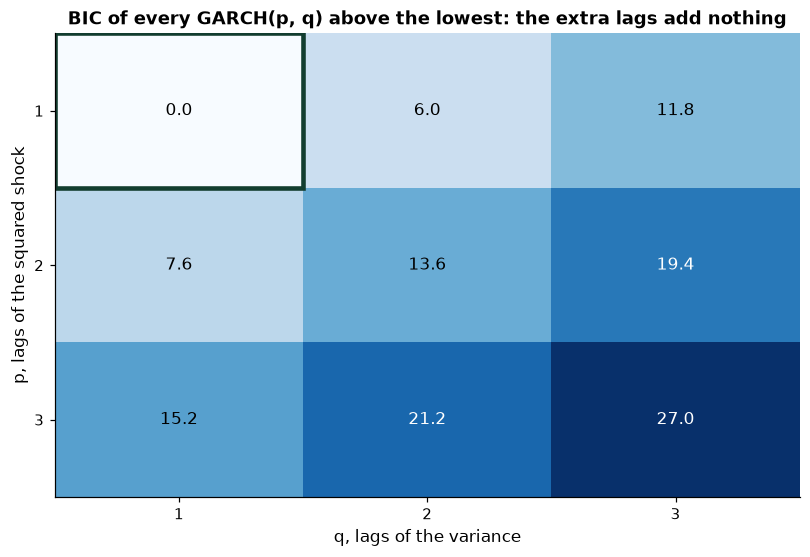

In [33]:
# BIC of a GARCH(p, q) above the lowest, for p down and q across; the lowest cell is outlined
fig, ax = plt.subplots(figsize=(7.5, 5.2))
matrix = pq_above.to_numpy(dtype=float)
image = ax.imshow(matrix, cmap="Blues", aspect="auto", vmin=0, vmax=np.nanmax(matrix))
for row in range(3):
    for column in range(3):
        dark = matrix[row, column] > 0.6 * np.nanmax(matrix)
        ax.text(column, row, f"{matrix[row, column]:.1f}", ha="center", va="center", fontsize=11, color="white" if dark else "black")
best_row, best_col = np.unravel_index(np.nanargmin(matrix), matrix.shape)
ax.add_patch(plt.Rectangle((best_col - 0.5, best_row - 0.5), 1, 1, fill=False, edgecolor=plotkit.GREEN_DARK, linewidth=3))
ax.set_xticks(range(3), [1, 2, 3])
ax.set_yticks(range(3), [1, 2, 3])
ax.set_xlabel("q, lags of the variance")
ax.set_ylabel("p, lags of the squared shock")
ax.set_title("BIC of every GARCH(p, q) above the lowest: the extra lags add nothing")
ax.grid(False)
fig.tight_layout()
plt.show()

* How to read it: each cell is the BIC above the lowest, so the outlined cell is 0, at (p, q) = (1, 1). Every other order is at least 6.0 units worse, and the cost rises with each extra lag. Orders of 1 and 1 are the standard for a reason. Orders that did not converge: 0 of 9.

## 7.5 Walk-Forward GARCH

**How it works.** Walk-forward scoring of a GARCH is day 2's recipe with a model in the middle. In each fold a normal GARCH(1,1) is **fitted once**, on the training changes only. Then the variance recursion runs on from the variance of the last training row, through the fold's rows, with the coefficients held fixed: the variance for a test date uses the shocks before it, so it uses nothing from the date itself. What is scored is the model's value for the size of the change, its volatility times 0.7979, against the absolute change. At the next fold the model is fitted again on a longer window. You control the folds; what comes out is a table of MAE and RMSE by fold and one volatility per test date. The proof of `walk_forward_score` runs on every fold: no volatility may move when the rows from the middle of the fold on are removed.

Q. Add `walk_forward_garch`, and the rest of today's tests.

In [34]:
%%writefile -a tskit.py


def walk_forward_garch(changes: pd.Series, splits, check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score a GARCH(1,1)'s one-step volatility fold by fold, walk-forward, against the size of each change.

    Inputs: changes, a dated Series of daily changes in bp with no NaN; splits, from mlkit.walk_forward_splits with gap 0
    and positions in this series; check, as for walk_forward_score.
    Each fold fits a normal GARCH(1,1) once, on its training rows only, then runs the variance recursion over the fold's
    rows from the last training row's variance, with the coefficients held fixed: the volatility for a test row uses
    only the rows before it. What is scored is the model's value for the absolute change, ABS_SCALE x the volatility,
    against the absolute change: MAE and RMSE by fold, as walk_forward_score computes them.
    Output: (scores, volatility): the scores table, and the fitted volatility in bp for every test date (NaN elsewhere).
    Raises what fit_garch and walk_forward_score raise.
    """
    fitted = {}

    def fit_one(history_abs: pd.Series, n_train: int) -> np.ndarray:
        # the signed changes with the same rows blank as the (possibly cut) history the proof hands over
        signed = changes.iloc[:len(history_abs)].to_numpy(dtype=float).copy()
        signed[np.isnan(history_abs.to_numpy())] = np.nan
        if n_train not in fitted:
            fitted[n_train] = fit_garch(changes.iloc[:n_train].to_numpy())
        result = fitted[n_train]
        mu, omega, alpha, beta = (float(v) for v in np.asarray(result.params)[:4])
        variance = garch_variance(signed[n_train - 1:], mu, omega, alpha, beta, float(result.conditional_volatility[-1]) ** 2)
        return ABS_SCALE * np.sqrt(variance[1:])

    scores, values = walk_forward_score(changes.abs(), fit_one, splits, check=check)
    return scores, values / ABS_SCALE

Appending to tskit.py


* It is `walk_forward_score` on the **absolute** changes with a rule: `fit_one` fits once, shares the fit with the proof's second run, and runs `garch_variance` from the last training variance. The signed changes are masked the same way the proof masks the absolute ones, so a removed row stops the recursion at that row.
* It returns the scores and the fitted volatility in bp for every test date.

Q. Write the tests: no volatility before a changed row moves, the GARCH is closer than a constant size on a seeded GARCH, and the refusals.

In [35]:
%%writefile -a test_tskit.py


def test_walk_forward_garch_uses_only_the_past():
    series = garch_series(rows=400)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=200, test_size=60)
    _, volatility = tskit.walk_forward_garch(series, splits)
    # change every row from position 270 on: no value dated before position 270 may move
    other = series.copy()
    other.iloc[270:] = other.iloc[270:] * 3.0
    _, again = tskit.walk_forward_garch(other, splits, check=False)
    assert volatility.iloc[:270].equals(again.iloc[:270])
    assert not volatility.iloc[270:280].equals(again.iloc[270:280])


def test_walk_forward_garch_is_closer_than_a_constant_size():
    series = garch_series()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=600, test_size=300)
    scores, volatility = tskit.walk_forward_garch(series, splits)
    size = series.abs()
    for number, (train, test) in enumerate(splits, start=1):
        constant = tskit.mae(size.iloc[test], np.full(len(test), size.iloc[train].mean()))
        assert scores.loc[number, "mae"] < constant
    assert volatility.iloc[:600].isna().all()


def test_fit_garch_refusals():
    values = garch_series().to_numpy()
    with pytest.raises(ValueError, match="at least 100"):
        tskit.fit_garch(values[:50])
    blank = values.copy()
    blank[7] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_garch(blank)

Appending to test_tskit.py


Q. Reload the modules and run the tests.

In [36]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print(f"walk_forward_garch in tskit: {hasattr(tskit, 'walk_forward_garch')}")

walk_forward_garch in tskit: True


In [37]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........................................                                 [100%]
40 passed in 5.73s



* `40 passed`: day 6's 34 and today's six.

Q. Score four rules for the size of the change on three series, walk-forward on the five folds: a constant size, a 20-row average, RiskMetrics' EWMA, and the GARCH(1,1).

In [38]:
def rule_values(name, rule):
    """Walk-forward MAE by fold of one rule's value for the absolute change, with the proof of walk_forward_score on every fold."""
    size = changes[name].abs()
    if rule == "constant size":
        found = tskit.walk_forward_score(size, lambda history, n_train: np.full(len(history) - n_train, history.iloc[:n_train].mean()), splits)
    elif rule == "20-row average":
        found = tskit.walk_forward_score(size, lambda history, n_train: history.rolling(20).mean().shift(1).iloc[n_train:].to_numpy(), splits)
    elif rule == "EWMA, lambda 0.94":
        found = tskit.walk_forward_score(size, lambda history, n_train: (np.sqrt((history ** 2).ewm(alpha=0.06, adjust=False).mean()).shift(1)
                                                                          * tskit.ABS_SCALE).iloc[n_train:].to_numpy(), splits)
    else:
        scores_g, volatility_g = tskit.walk_forward_garch(changes[name], splits)
        return scores_g["mae"].to_list(), volatility_g
    return found[0]["mae"].to_list(), None


RULES = ["constant size", "20-row average", "EWMA, lambda 0.94", "GARCH(1,1)"]
mae_by_fold, garch_volatility = {}, {}
for name in ["10 Yr", "2s10s", "IG"]:
    table = {}
    for rule in RULES:
        table[rule], vol = rule_values(name, rule)
        if vol is not None:
            garch_volatility[name] = vol
    mae_by_fold[name] = pd.DataFrame(table, index=pd.Index(range(1, len(splits) + 1), name="fold"))

size_rows = []
for name, table in mae_by_fold.items():
    for rule in RULES[1:]:
        size_rows.append({"series": name, "rule": rule, "mean MAE (bp)": table[rule].mean(), "constant size (bp)": table["constant size"].mean(),
                          "gap to the constant (bp)": table[rule].mean() - table["constant size"].mean(),
                          "ratio to the constant": table[rule].mean() / table["constant size"].mean(),
                          "folds below the constant": int((table[rule] < table["constant size"]).sum()),
                          "folds of the constant, range (bp)": table["constant size"].max() - table["constant size"].min()})
size_table = pd.DataFrame(size_rows).set_index(["series", "rule"])
print(size_table[["mean MAE (bp)", "gap to the constant (bp)", "ratio to the constant", "folds below the constant"]].round(4).to_string())

plotkit.styled(size_table, ["ratio to the constant"], "Three series: walk-forward MAE of three rules for the size of the daily change, against a constant size, day 2's five folds",
               higher_is_better=False, fmt="{:.4f}")

                          mean MAE (bp)  gap to the constant (bp)  ratio to the constant  folds below the constant
series rule                                                                                                       
10 Yr  20-row average            2.0402                   -0.0899                 0.9578                         3
       EWMA, lambda 0.94         2.0437                   -0.0864                 0.9594                         3
       GARCH(1,1)                2.0671                   -0.0631                 0.9704                         3
2s10s  20-row average            1.4588                   -0.0387                 0.9741                         3
       EWMA, lambda 0.94         1.4538                   -0.0438                 0.9708                         3
       GARCH(1,1)                1.4593                   -0.0383                 0.9745                         3
IG     20-row average            0.5052                   -0.0005               

<styled table: Three series: walk-forward MAE of three rules for the size of the daily change, against a constant size, day 2's five folds>

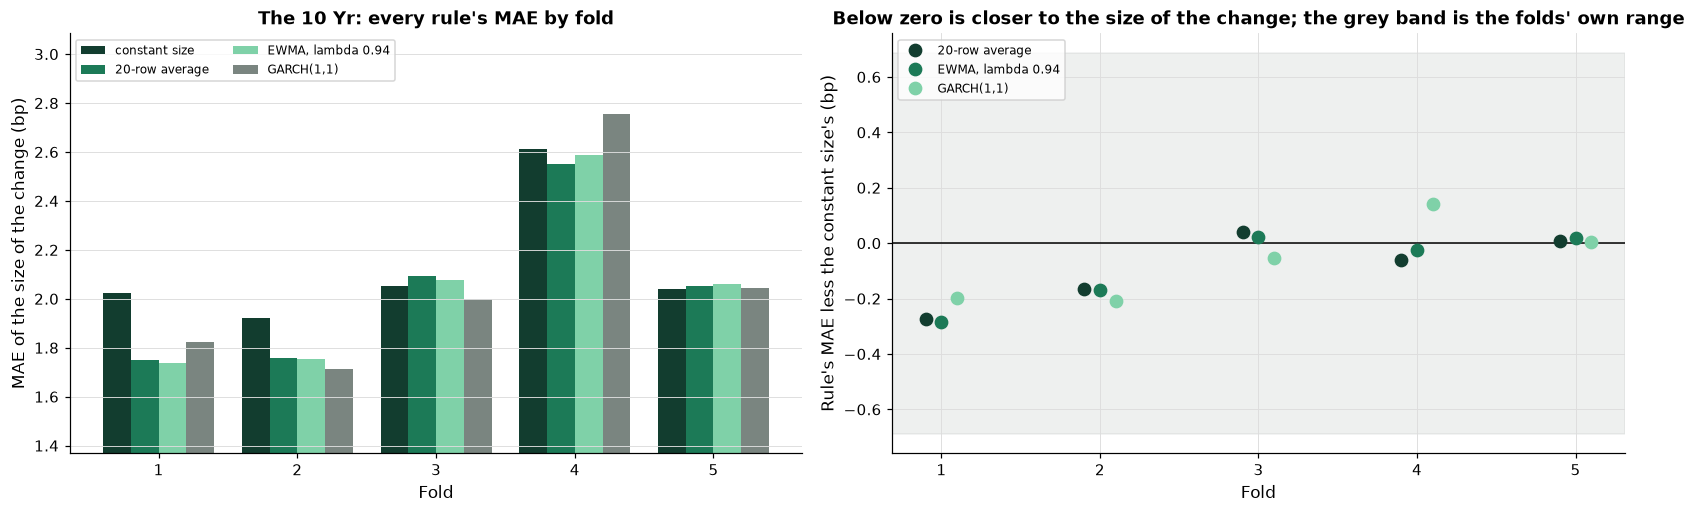

In [39]:
# left: each rule's MAE for the size of the 10 Yr's change, by fold; right: each rule's MAE less the constant size's, with the folds' range in grey
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 4.8))
table = mae_by_fold["10 Yr"]
width = 0.2
positions = table.index.to_numpy()
for number, column in enumerate(table.columns):
    left.bar(positions + (number - 1.5) * width, table[column], width, label=column)
left.set_xlabel("Fold")
left.set_ylabel("MAE of the size of the change (bp)")
left.set_title("The 10 Yr: every rule's MAE by fold")
left.set_xticks(positions)
left.set_ylim(table.to_numpy().min() * 0.8, table.to_numpy().max() * 1.12)
left.grid(axis="x", visible=False)
left.legend(fontsize=8, loc="upper left", ncol=2)
spread = table["constant size"].max() - table["constant size"].min()
right.axhspan(-spread, spread, color=plotkit.GREY, alpha=0.12)
right.axhline(0, color="black", linewidth=1)
for number, column in enumerate(table.columns[1:]):
    right.plot(positions + (number - 1) * 0.1, table[column] - table["constant size"], "o", markersize=8, label=column)
right.set_xlabel("Fold")
right.set_ylabel("Rule's MAE less the constant size's (bp)")
right.set_title("Below zero is closer to the size of the change; the grey band is the folds' own range")
right.set_xticks(positions)
right.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

* **Eight of the nine rule-and-series combinations are closer to the size of the change than a constant size**, by a small margin: the ratios run from 0.9578 to 1.0076, and the one above 1 is the EWMA on the IG spread. On the 10 Yr the constant is 2.1302 bp, the 20-row average 2.0402, the EWMA 2.0437, and the GARCH 2.0671.
* **The GARCH is the closest rule on one series of three.** On the 10 Yr the 20-row average is closest, on the 2s10s the EWMA, and on the IG spread the GARCH. A model with a recursion and a likelihood is not better than an average by construction; the scores decide.
* **The gains are a few percent and the folds do not agree on them.** The 10 Yr's GARCH is 3.0 percent closer than the constant on average, and below it on 3 of 5 folds; the constant's own folds differ by 0.69 bp. Part of the reason is the target: the size of one day's change is noisy around its volatility, so even a perfect volatility cannot make the absolute change on a given day close to it.

Q. Why is the GARCH not closer? Read the coefficients each fold's model was fitted with.

In [40]:
# the GARCH(1,1) the walk-forward scores used in each fold: fitted on that fold's training changes only
fold_rows = []
for number, (train, test) in enumerate(splits, start=1):
    fit = tskit.fit_garch(changes["10 Yr"].iloc[train].to_numpy())
    mu_f, omega_f, alpha_f, beta_f = (float(v) for v in np.asarray(fit.params)[:4])
    # the optimiser's last digits can move with the machine, so 3 decimals for the weights and 2 for the volatilities
    fold_rows.append({"fold": number, "changes fitted": len(train), "alpha": round(alpha_f, 3), "beta": round(beta_f, 3), "persistence": round(alpha_f + beta_f, 3),
                      "long-run volatility (bp)": round(float(np.sqrt(omega_f / (1 - alpha_f - beta_f))), 2),
                      "standard deviation of the training changes (bp)": round(float(changes["10 Yr"].iloc[train].std()), 2)})
fold_params = pd.DataFrame(fold_rows).set_index("fold")
print(fold_params.to_string())

plotkit.styled(fold_params, [], "The GARCH(1,1) of each fold: fitted on that fold's training changes of the 10 Yr", fmt="{:.3f}")

      changes fitted  alpha   beta  persistence  long-run volatility (bp)  standard deviation of the training changes (bp)
fold                                                                                                                      
1                503  0.000  0.996        0.996                      3.90                                             4.95
2                755  0.000  0.998        0.998                      0.01                                             4.52
3               1007  0.000  0.997        0.997                      3.20                                             4.31
4               1259  0.009  0.986        0.995                      3.91                                             4.30
5               1511  0.087  0.849        0.936                      4.38                                             4.52


,changes fitted,alpha,beta,persistence,long-run volatility (bp),standard deviation of the training changes (bp)
fold,,,,,,
1,503,0.000,0.996,0.996,3.900,4.950
2,755,0.000,0.998,0.998,0.010,4.520
3,"1,007",0.000,0.997,0.997,3.200,4.310
4,"1,259",0.009,0.986,0.995,3.910,4.300
5,"1,511",0.087,0.849,0.936,4.380,4.520


* **Folds 1 to 3 found no clustering to fit.** Their alpha is 0.000, 0.000, and 0.000, with a beta near 0.996: a model that barely reacts to a shock and barely forgets one, which is close to a constant variance. The first 503 to 1,007 changes (2015 to 2018) had too little clustering for a GARCH to find alpha, which needs storms. Folds 4 and 5, with more storms in training, have alpha 0.009 and 0.087.
* A GARCH also pulls its variance back toward the long-run level it learned in training (3.91 bp in fold 4). When a fold's test dates are more volatile than its training dates were, as in fold 4, that pull works against it. The EWMA has no long-run level, and follows the storm.
* **A fit on a few hundred rows is fragile.** It is why the walk-forward scores of a GARCH are a different thing from its in-sample fit in section 7.2, which used all 2,000 changes.

Q. A second yardstick scores the whole shape of the distribution: the average Gaussian log score of the signed change, where each rule gives a volatility for the day.

In [41]:
# a second yardstick for the 10 Yr: the average Gaussian log score of the signed change, each rule's volatility with the training mean as the average
def log_score_by_fold(name):
    """Mean log score per fold (higher is better) for the four rules: the value the rule gives for the volatility of each test date."""
    signed = changes[name]
    scores = {rule: [] for rule in RULES}
    _, garch_vol_wf = tskit.walk_forward_garch(signed, splits)
    for train, test in splits:
        centre = signed.iloc[train].mean()
        rule_vol = {
            "constant size": pd.Series(signed.iloc[train].std(), index=signed.index),
            "20-row average": signed.rolling(20).std().shift(1),
            "EWMA, lambda 0.94": np.sqrt((signed ** 2).ewm(alpha=0.06, adjust=False).mean()).shift(1),
            "GARCH(1,1)": garch_vol_wf,
        }
        for rule, vol in rule_vol.items():
            sigma = vol.iloc[test].to_numpy()
            miss = signed.iloc[test].to_numpy() - centre
            scores[rule].append(float(np.mean(-0.5 * np.log(2 * np.pi * sigma ** 2) - miss ** 2 / (2 * sigma ** 2))))
    return pd.DataFrame(scores, index=pd.Index(range(1, len(splits) + 1), name="fold"))


log_scores = log_score_by_fold("10 Yr")
log_summary = pd.DataFrame({"mean log score per day": log_scores.mean(), "gain over the constant size": log_scores.mean() - log_scores["constant size"].mean(),
                            "folds above the constant": (log_scores.gt(log_scores["constant size"], axis=0)).sum()})
log_summary.index.name = "rule"
print(log_summary.round(4).to_string())

plotkit.styled(log_summary, ["mean log score per day"], "The 10 Yr: mean log score of the signed change by walk-forward volatility rule (higher is better)", fmt="{:.4f}")

                   mean log score per day  gain over the constant size  folds above the constant
rule                                                                                            
constant size                     -2.8946                       0.0000                         0
20-row average                    -2.8494                       0.0452                         2
EWMA, lambda 0.94                 -2.8273                       0.0673                         3
GARCH(1,1)                        -2.8781                       0.0165                         3


,mean log score per day,gain over the constant size,folds above the constant
rule,,,
constant size,-2.8946,0.0000,0
20-row average,-2.8494,0.0452,2
"EWMA, lambda 0.94",-2.8273,0.0673,3
"GARCH(1,1)",-2.8781,0.0165,3


* On a log score every rule beats the constant size on average: the gain is **0.067 per day for the EWMA**, 0.045 for the 20-row average, and **0.016 for the GARCH**. A log score punishes a volatility that is too small on a big day much harder than MAE does, so it sees clustering more clearly, and it ranks the EWMA first. Fold 4 (test dates 2020-01-16 to 2021-01-19, which include the highest 20-row volatility of the development years, on 2020-03-26) accounts for most of it: the EWMA gains 0.240 there, the GARCH 0.114. The GARCH is above the constant size on 3 of 5 folds.

Q. Draw the last fold's first 120 test dates: the size of each change, the constant size, and the GARCH value for the size.

In [42]:
# the last fold's first 120 test dates: the size of each change, the constant size, and the GARCH value for the size
last_test = splits[-1][1]
size_actual = changes["10 Yr"].abs().iloc[last_test]
garch_size = garch_volatility["10 Yr"].iloc[last_test] * tskit.ABS_SCALE
constant_size = changes["10 Yr"].abs().iloc[splits[-1][0]].mean()
print(f"last fold: the average size {size_actual.mean():.3f} bp; the constant {constant_size:.3f} bp; the GARCH value ran from {garch_size.min():.3f} to {garch_size.max():.3f} bp")
print(f"correlation of the GARCH value with the size of the change on the {len(last_test)} dates: {np.corrcoef(garch_size, size_actual)[0, 1]:.3f}")

last fold: the average size 3.409 bp; the constant 3.391 bp; the GARCH value ran from 2.640 to 5.220 bp
correlation of the GARCH value with the size of the change on the 252 dates: 0.103


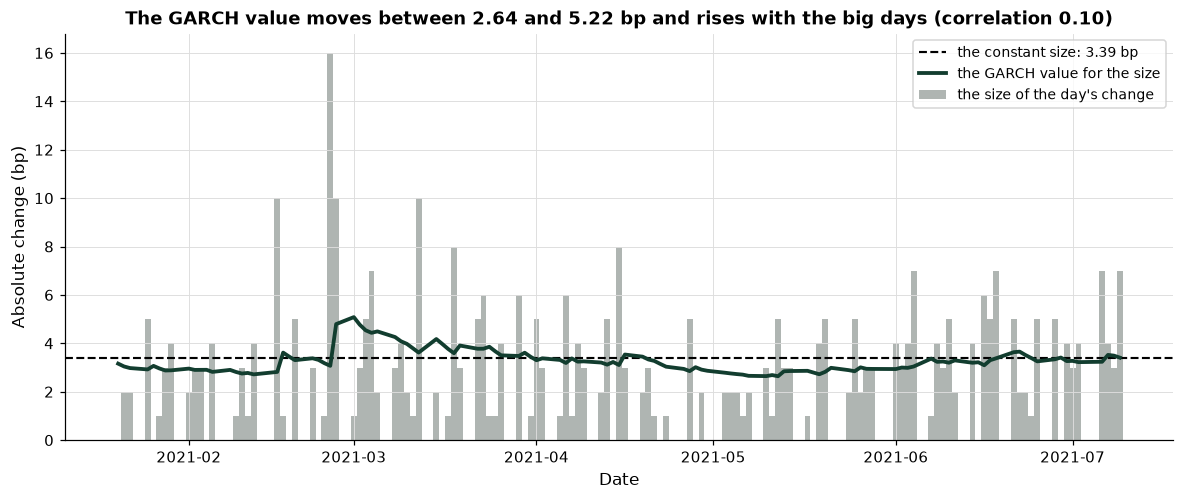

In [43]:
# the last fold's first 120 test dates: the size of each change in grey, the constant size as a line, and the GARCH value for the size in green
fig, ax = plt.subplots(figsize=(13, 4.8))
dates_last = size_actual.index[:120]
ax.bar(dates_last, size_actual.iloc[:120], color=plotkit.GREY, width=1.0, alpha=0.6, label="the size of the day's change")
ax.axhline(constant_size, color="black", linewidth=1.4, linestyle="--", label=f"the constant size: {constant_size:.2f} bp")
ax.plot(dates_last, garch_size.iloc[:120], color=plotkit.GREEN_DARK, linewidth=2.5, label="the GARCH value for the size")
ax.set_xlabel("Date")
ax.set_ylabel("Absolute change (bp)")
ax.set_title(f"The GARCH value moves between {garch_size.min():.2f} and {garch_size.max():.2f} bp and rises with the big days (correlation {np.corrcoef(garch_size, size_actual)[0, 1]:.2f})")
ax.legend(loc="upper right", fontsize=9)
plt.show()

* The constant size is a flat line at 3.39 bp. The GARCH value rises with each cluster of big days and falls in quiet stretches, between 2.64 and 5.22 bp, and its correlation with the size of the change on the 252 dates is 0.10. That is far from 1: **the model knows a little about how big the days tend to be, and nothing about how big a given day is.**

Q. The contrast with day 5: the level of the 10 Yr's change against its size.

In [44]:
# the level of the change against its size, on the 10 Yr: day 5's AR(1) against the last value, and today's GARCH against a constant size
level_scores, _ = tskit.walk_forward_arima(changes["10 Yr"], (1, 0, 0), splits)
level_zero = np.mean([changes["10 Yr"].iloc[test].abs().mean() for _, test in splits])
contrast = pd.DataFrame({
    "model": ["AR(1)", "GARCH(1,1)"], "baseline": ["the last value (a change of zero)", "a constant size"],
    "model MAE (bp)": [level_scores["mae"].mean(), mae_by_fold["10 Yr"]["GARCH(1,1)"].mean()],
    "baseline MAE (bp)": [level_zero, mae_by_fold["10 Yr"]["constant size"].mean()],
}, index=pd.Index(["the level of the change", "the size of the change"], name="what is described"))
contrast["ratio"] = contrast["model MAE (bp)"] / contrast["baseline MAE (bp)"]
print(contrast.round(4).to_string())

plotkit.styled(contrast, ["ratio"], "The 10 Yr: a model of the level of the change and of its size, each against its baseline, day 2's five folds",
               higher_is_better=False, fmt="{:.4f}")

                              model                           baseline  model MAE (bp)  baseline MAE (bp)   ratio
what is described                                                                                                
the level of the change       AR(1)  the last value (a change of zero)          3.2026             3.1937  1.0028
the size of the change   GARCH(1,1)                    a constant size          2.0671             2.1302  0.9704


,model,baseline,model MAE (bp),baseline MAE (bp),ratio
what is described,,,,,
the level of the change,AR(1),the last value (a change of zero),3.2026,3.1937,1.0028
the size of the change,"GARCH(1,1)",a constant size,2.0671,2.1302,0.9704


* **The level of the change: a ratio of 1.0028** (day 5's AR(1) against the last value): no closer. **The size of the change: 0.9704** (the GARCH against a constant size): 3.0 percent closer. The two ratios are not on one scale, and the difference between them is the point. The past of a change told nothing about its sign or its amount, and told a little about its size. In the data the memory in the size is overwhelming (Ljung-Box p-values near 1e-100); in the scores it is worth a few percent, because one day's absolute change is a noisy sample of the day's volatility.
* **What this does not say.** It does not say a volatility model helps anyone choose a security or time anything. It describes how well a rule for the size of a change, fitted on earlier dates, would have matched the changes on later dates inside this file.

## What the Models Show, and Where They Fail

**What the models show.** On three daily series, rules that use the sizes of past changes were a few percent closer to the size of each change than a constant size, on the five-fold average, in eight of nine combinations. The GARCH(1,1) had ratios of 0.9704 on the 10 Yr, 0.9745 on the 2s10s slope, and 0.9725 on the invented IG spread, and was the closest rule on the IG spread only. Fitted to all the development years, the 10 Yr's persistence is 0.981 and the half-life of a shock 35.9 rows.

**Where they fail.**

* **On the level.** None of this says anything about whether a change is positive or negative: that was day 5, and the AR(1) did not beat the last value.
* **On the tails.** The normal model's standardized residuals have an excess kurtosis of 1.17: its tails are too thin. The t model fits better, and its degrees of freedom are 11.2.
* **On the persistence.** The 2 Yr's persistence is above 1 (the exercises), and a model with a persistence at 1 has no half-life and no long-run level.
* **On short windows.** The GARCH fitted to the first three folds' training changes found no clustering (alpha near 0), and its walk-forward scores are those of a nearly constant variance.
* **On the margin.** The gains are a few percent in MAE and the folds do not agree on them.

**What the data cannot support.** Fitted volatility on past dates is a description of how big those days were. It is not evidence about any later date, and nothing here was fitted for or reported at a date after 2022-12-30.

**What was not tested.** Other distributions' effect on a score, an asymmetric or EGARCH model walk-forward, a refit at every date, other series, and the held-out years, which stay closed until the capstone.

## Excel Side by Side

**The GARCH variance is one recursive formula in Excel.** Excel has no GARCH fitter: the fit is the part it cannot do. Once the four coefficients are known, the model is a column. Each formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-21) on the 10 Yr's 2,000 development changes in bp: dates in column A, the change in B, the variance in C, the volatility in D. The coefficients sit in F1 (mu), F2 (omega), F3 (alpha), F4 (beta), and the first variance in F5. They are pasted from the fit above **rounded to 3 decimals** (0.071, 0.467, 0.066, 0.915), which is what a student can read off a table, and the first variance is the sample variance of the changes (25.286).

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Excel returned</th></tr>
<tr><td align="left">The first variance</td><td align="left"><code>changes.var()</code></td><td align="left"><code>=F5</code> in C2</td><td align="left">the sample variance</td></tr>
<tr><td align="left">Every later variance</td><td align="left"><code>garch_variance(...)</code></td><td align="left"><code>=$F$2+$F$3*(B2-$F$1)^2+$F$4*C2</code> in C3, filled down</td><td align="left">volatility 6.8197 bp on the last date</td></tr>
<tr><td align="left">The volatility</td><td align="left"><code>np.sqrt(variance)</code></td><td align="left"><code>=SQRT(C2)</code> in D2, filled down</td><td align="left">the same column</td></tr>
<tr><td align="left">The persistence</td><td align="left"><code>pasted['alpha'] + pasted['beta']</code></td><td align="left"><code>=F3+F4</code></td><td align="left">0.981000</td></tr>
<tr><td align="left">The half-life of a shock</td><td align="left"><code>garch_half_life(alpha, beta)</code></td><td align="left"><code>=LN(0.5)/LN(F3+F4)</code></td><td align="left">36.1337 rows</td></tr>
<tr><td align="left">The long-run volatility</td><td align="left"><code>np.sqrt(omega / (1 - alpha - beta))</code></td><td align="left"><code>=SQRT(F2/(1-F3-F4))</code></td><td align="left">4.9577 bp</td></tr>
<tr><td align="left">MAE of the size, in-sample</td><td align="left"><code>np.abs(size - ABS_SCALE * vol).mean()</code></td><td align="left"><code>=SUMPRODUCT(ABS(ABS(B3:B2001)-SQRT(2/PI())*D3:D2001))/ROWS(B3:B2001)</code></td><td align="left">2.2991 bp</td></tr>
</table>
<br clear="left">

**The recursion is a column.** Write the first variance in C2, then in C3 `=$F$2+$F$3*(B2-$F$1)^2+$F$4*C2`: omega, plus alpha times the squared shock of the row above (the change less mu, squared), plus beta times the variance of the row above. The `$` signs hold the four coefficients fixed while the formula fills down. Every row uses only the rows above it, which is the walk-forward rule in a spreadsheet. Change F3 and F4 by hand and the whole column redraws: the fastest way to feel what alpha and beta do. Excel's column equals the Python recursion with the same pasted numbers to 1e-8. Against `arch`'s own volatility, which used the unrounded coefficients and its own first variance, the pasted column is within 0.9 bp on all rows and within 0.0 bp after the first 200: the starting value fades, and the rounding stays.

**The half-life is one cell**, `=LN(0.5)/LN(F3+F4)`: 36.1 rows for the 10 Yr with the rounded coefficients (35.9 with the unrounded ones). And the size score in the last row is `SUMPRODUCT` of `ABS`, with `SQRT(2/PI())` the factor that turns a volatility into an average absolute shock. What Excel cannot do is the maximum-likelihood fit itself, or refit it on each fold; Solver can maximise a likelihood written in cells, one fold at a time, and a library does it in a line.

Q. Do Excel's values equal Python's?

In [45]:
# Excel's results, from the course's Excel check, beside Python's with the same pasted coefficients
excel_side = pd.DataFrame({
    "Excel": [6.819665041929055, 0.9810000000000001, 36.13374892920289, 4.957715942691874, 2.2990523066035737],
    "Python": [pasted_vol[-1], pasted["alpha"] + pasted["beta"], tskit.garch_half_life(pasted["alpha"], pasted["beta"]),
               np.sqrt(pasted["omega"] / (1 - pasted["alpha"] - pasted["beta"])),
               np.abs(changes["10 Yr"].abs().to_numpy()[1:] - tskit.ABS_SCALE * pasted_vol[1:]).mean()],
}, index=pd.Index(["volatility on the last date (bp)", "persistence", "half-life of a shock (rows)", "long-run volatility (bp)", "in-sample MAE of the size (bp)"],
                   name="Quantity"))
excel_side["equal within 1e-8"] = (excel_side["Excel"] - excel_side["Python"]).abs() < 1e-8
plotkit.styled(excel_side, [], "Excel beside Python for the 10 Yr's GARCH(1,1) with the same pasted coefficients: the volatility, persistence, half-life, long-run level, and in-sample MAE", fmt="{:.6f}")

,Excel,Python,equal within 1e-8
Quantity,,,
volatility on the last date (bp),6.819665,6.819665,True
persistence,0.981000,0.981000,True
half-life of a shock (rows),36.133749,36.133749,True
long-run volatility (bp),4.957716,4.957716,True
in-sample MAE of the size (bp),2.299052,2.299052,True


* Every quantity is equal to within 1e-8.

## Save the Day with Git

Today's Git step is a rename. A file gets a better name, and Git follows the file's history through the rename.

Q. Start a repository in the work folder, and commit the code.

In [46]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [47]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5b_07_ab1259f4 and nowhere else


In [48]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [49]:
!git -C "{work}" add .gitignore mlkit.py tskit.py test_tskit.py
!git -C "{work}" commit -q -m "Day 7: tskit with garch_half_life, fit_garch, garch_variance, and walk_forward_garch"
!git -C "{work}" show --stat --format=%s HEAD

Day 7: tskit with garch_half_life, fit_garch, garch_variance, and walk_forward_garch

 .gitignore    |   3 +
 mlkit.py      | 568 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_tskit.py | 493 +++++++++++++++++++++++++++++++++++++++++++++++++
 tskit.py      | 582 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 4 files changed, 1646 insertions(+)


Q. Save the four GARCH coefficients and commit them.

In [50]:
# the fitted GARCH(1,1) coefficients as a file: 4 decimals and LF line endings
garch_table.iloc[:4, :1].round(4).to_csv("garch.csv", lineterminator="\n")
print((work / "garch.csv").read_text(encoding="utf-8"))

Quantity,value
"mu, the average change (bp)",0.071
"omega, the constant (bp squared)",0.467
"alpha, the weight on the latest squared shock",0.066
"beta, the weight on the variance before",0.915



In [51]:
!git -C "{work}" add garch.csv
!git -C "{work}" commit -q -m "Day 7: GARCH coefficients"

Q. The file should say what it holds. Rename it with `git mv` and commit.

In [52]:
# git mv renames the file and stages the rename: R in the status means renamed
!git -C "{work}" mv garch.csv garch_10yr_coefficients.csv
!git -C "{work}" status --short
!git -C "{work}" commit -q -m "Day 7: rename the coefficients file"

R  garch.csv -> garch_10yr_coefficients.csv
?? course3_synthetic_spreads.csv
?? plotkit.py
?? treasury_par_yields.csv


Q. Does the history follow the file under its new name?

In [53]:
# a plain log of the new name stops at the rename; --follow keeps going back through it
!git -C "{work}" log --oneline -- garch_10yr_coefficients.csv
!git -C "{work}" log --oneline --follow -- garch_10yr_coefficients.csv

8f267cc Day 7: rename the coefficients file


8f267cc Day 7: rename the coefficients file
078f3a8 Day 7: GARCH coefficients


* The plain `log` lists only the rename commit, because under its new name the file did not exist before it. `--follow` finds the earlier commit under the old name. A rename is a change Git can follow, but only when you ask.

## Bring It Home

Add today's functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Open `tskit.py` and paste the code of today's three `tskit.py` cells (sections 7.2 and 7.5) at the end, without their first lines. Do the same for the three `test_tskit.py` cells in `test_tskit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_tskit.py
```

The last line says `40 passed`.

**Step 4.** Commit.

```powershell
git add tskit.py test_tskit.py
git commit -m "Day 7: tskit with garch_half_life, fit_garch, garch_variance, and walk_forward_garch"
```

## You Can Now

* Show that the size of a change has long memory when its sign has none, with the ACF of squares and absolute values and a Ljung-Box test.
* Read a GARCH(1,1): the variance recursion in one Excel formula, alpha, beta, persistence, the half-life of a shock, and the long-run volatility.
* Draw rolling, EWMA, and GARCH volatility on one chart and say how they differ.
* Read every setting of `arch_model`, and choose a distribution, a variance model, and an order from a table and a heatmap.
* Score a walk-forward GARCH (`walk_forward_garch`) against a constant size, a 20-row average, and the EWMA, and read the gap against how far the folds differ.
* Say plainly what changed from day 5: the level of the 10 Yr's change was no closer than the last value (ratio 1.0028), and the size was a few percent closer than a constant (ratio 0.9704), with the GARCH the closest of four rules on one series of three.

Next, week 2, day 3: lag features and gradient boosting, a model that can use many inputs at once, scored in the same tables.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the five series, makes day 2's five folds on the changes (`changes`, `splits`), and defines `check`, a small function that marks your answers.

In [54]:
# the Treasury curve (percent) and the course's synthetic spreads (bp): one row per date, the same dates in both files
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"]).set_index("date")
print(f"Treasury file: {len(treasury):,} dates; spread file: {len(spreads):,} dates; same dates: {treasury.index.equals(spreads.index)}")

# the development and held-out years, set now, before any model is fitted
DEVELOPMENT_END = "2022-12-30"
development = treasury.loc[:DEVELOPMENT_END]
dev_spreads = spreads.loc[:DEVELOPMENT_END]
held_out_dates = treasury.index[treasury.index > DEVELOPMENT_END]
print(f"development years: {len(development):,} dates, {development.index[0].date()} to {development.index[-1].date()}")
print(f"held-out years: {len(held_out_dates):,} dates, {held_out_dates[0].date()} to {held_out_dates[-1].date()}, not opened until the capstone")

# five series, all in bp: yields times 100 (rounded to the file's two decimals of a percent), spreads as they are
levels = pd.DataFrame({
    "2 Yr": (development["2 Yr"] * 100).round(2),
    "10 Yr": (development["10 Yr"] * 100).round(2),
    "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
    "IG": dev_spreads["ig_spread_bp"],
    "HY": dev_spreads["hy_spread_bp"],
})
# nothing below reads a held-out row: drop the full tables
del treasury, spreads, development, dev_spreads
print(f"five series in bp: {list(levels.columns)}; blank cells: {int(levels.isna().sum().sum())}")

# the walk-forward windows of section 2.5, used by every later day: fit on 504 dates first, then score 252 at a time
MIN_TRAIN, TEST_SIZE = 504, 252
# day 2's folds on the levels' dates; the change series starts one row later, so each fold's positions shift down by one
changes = levels.diff().dropna()
level_splits = mlkit.walk_forward_splits(levels.index, min_train=MIN_TRAIN, test_size=TEST_SIZE)
splits = [(train[1:] - 1, test - 1) for train, test in level_splits]
for number, (train, test) in enumerate(splits, start=1):
    mlkit.assert_past_only(changes.index[train], changes.index[test])
    print(f"fold {number}: fit on {len(train)} changes to {changes.index[train[-1]].date()}, "
          f"score {len(test)} from {changes.index[test[0]].date()} to {changes.index[test[-1]].date()}")

# the size of a change is its absolute value: the average size in each fold is the constant day 2's MAE of a zero change measures
size_mae = pd.DataFrame({column: [changes[column].iloc[test].abs().mean() for _, test in splits] for column in changes.columns},
                        index=pd.Index(range(1, len(splits) + 1), name="fold"))
print(size_mae.mean().round(4).to_string())


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

Treasury file: 2,940 dates; spread file: 2,940 dates; same dates: True
development years: 2,001 dates, 2015-01-02 to 2022-12-30
held-out years: 939 dates, 2023-01-03 to 2026-10-02, not opened until the capstone
five series in bp: ['2 Yr', '10 Yr', '2s10s', 'IG', 'HY']; blank cells: 0
fold 1: fit on 503 changes to 2017-01-05, score 252 from 2017-01-06 to 2018-01-08
fold 2: fit on 755 changes to 2018-01-08, score 252 from 2018-01-09 to 2019-01-11
fold 3: fit on 1007 changes to 2019-01-11, score 252 from 2019-01-14 to 2020-01-15
fold 4: fit on 1259 changes to 2020-01-15, score 252 from 2020-01-16 to 2021-01-19
fold 5: fit on 1511 changes to 2021-01-19, score 252 from 2021-01-20 to 2022-01-19
2 Yr     2.1881
10 Yr    3.1937
2s10s    2.1548
IG       0.8017
HY       3.5018


### Exercise 1

Q. Fit a GARCH(1,1) to the 2 Yr's 2,000 development changes with `tskit.fit_garch` and store its persistence, alpha + beta, rounded to 4 decimals, in **ex1_persistence**. Then try `tskit.garch_half_life` on its alpha and beta. What happens, and what does it say about the model?

In [55]:
ex1_persistence = ...

In [56]:
check("Exercise 1 persistence of the 2 Yr", ex1_persistence, 1.0)

Exercise 1 persistence of the 2 Yr: not attempted yet


### Exercise 2

Q. Add a function to your module. `long_run_volatility(omega, alpha, beta)` returns the volatility a GARCH(1,1) settles at, `sqrt(omega / (1 - alpha - beta))`. It refuses an omega that is not positive and a persistence that is not strictly between 0 and 1 with `ValueError`. Write the docstring first. Add `test_long_run_volatility`, which checks a value and that the recursion stops moving there, and the refusals. Run pytest, reload the module, and store the long-run volatility of the 10 Yr's GARCH(1,1), rounded to 2 decimals, in **ex2_long_run**.

Write the function in the cell that starts with `%%writefile -a tskit.py` and the test in the one that starts with `%%writefile -a test_tskit.py`, and run each of those cells once.

In [57]:
%%writefile -a tskit.py


# Exercise 2: write long_run_volatility(omega, alpha, beta) below this line

Appending to tskit.py


In [58]:
%%writefile -a test_tskit.py


# Exercise 2: write test_long_run_volatility() below this line

Appending to test_tskit.py


In [59]:
# run pytest, reload the module, then use your function on the 10 Yr's fitted coefficients
ex2_long_run = ...

In [60]:
check("Exercise 2 long-run volatility of the 10 Yr, bp", ex2_long_run, 4.94)

Exercise 2 long-run volatility of the 10 Yr, bp: not attempted yet


### Exercise 3

Q. Score a walk-forward GARCH(1,1) on the invented IG spread's changes with `tskit.walk_forward_garch(changes["IG"], splits)`, and store the ratio of its five-fold average MAE to the constant size's (`size_mae["IG"].mean()`), rounded to 3 decimals, in **ex3_ratio**. Is it above or below 1?

In [61]:
ex3_ratio = ...

In [62]:
check("Exercise 3 ratio of the GARCH to a constant size, IG", ex3_ratio, 0.613)

Exercise 3 ratio of the GARCH to a constant size, IG: not attempted yet


### Exercise 4

Q. Fit the 10 Yr's changes with Student's t shocks, `tskit.fit_garch(values, dist="t")`, and store the degrees of freedom (`params["nu"]`), rounded to 1 decimal, in **ex4_nu**. Is the tail heavier than a normal's? (A t with more than about 30 degrees of freedom is close to a normal.)

In [63]:
ex4_nu = ...

In [64]:
check("Exercise 4 degrees of freedom of the t shock, 10 Yr", ex4_nu, 11.2)

Exercise 4 degrees of freedom of the t shock, 10 Yr: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that returns the fitted GARCH volatility of a series of levels' daily changes, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
The fitted GARCH(1,1) volatility of a series of levels' daily changes, in bp, for every date.

    levels is a dated Series of levels in bp with no blank. The model is a normal GARCH(1,1) with a constant mean, fitted to the
    daily changes of the levels.
    Returns a Series of the fitted volatility in bp, one value for each change (the first date has no change).
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns a Series, and contains one bug.

In [65]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def fitted_volatility(levels):
    """The fitted GARCH(1,1) volatility of a series of levels' daily changes, in bp, for every date.

    levels is a dated Series of levels in bp with no blank. The model is a normal GARCH(1,1) with a constant mean, fitted to the
    daily changes of the levels.
    Returns a Series of the fitted volatility in bp, one value for each change (the first date has no change).
    """
    from arch import arch_model

    result = arch_model(levels.to_numpy(), mean="Constant", vol="GARCH", p=1, q=1, rescale=False).fit(disp="off", update_freq=0)
    return pd.Series(result.conditional_volatility, index=levels.index)

Q. Before you run the next cell: a series of levels near 200 bp whose daily changes have a standard deviation of a few bp. About how big should the fitted volatility be, and what does the function return?

In [66]:
rng = np.random.default_rng(SEED)
series = pd.Series(200 + rng.normal(0, 3, 800).cumsum(), index=pd.bdate_range("2020-01-01", periods=800))
print(f"standard deviation of the daily changes {series.diff().std():.2f} bp; the function's average volatility {fitted_volatility(series).mean():.2f} bp")

standard deviation of the daily changes 2.95 bp; the function's average volatility 21.15 bp


Q. Test the function against its docstring before you trust it.

In [67]:
# the test, written from the docstring before the code is trusted
rng = np.random.default_rng(SEED)
series = pd.Series(200 + rng.normal(0, 3, 800).cumsum(), index=pd.bdate_range("2020-01-01", periods=800))
volatility = fitted_volatility(series)
typical = series.diff().std()
assert volatility.mean() < 3 * typical, f"the average volatility is {volatility.mean():.1f} bp for a series whose daily changes have a standard deviation of {typical:.1f} bp: the model was not fitted to the changes"
print(f"average volatility {volatility.mean():.2f} bp against a standard deviation of the changes of {typical:.2f} bp")

AssertionError: the average volatility is 21.2 bp for a series whose daily changes have a standard deviation of 3.0 bp: the model was not fitted to the changes

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the fixed function's average volatility on the test series, rounded to 2 decimals, in **ex5_vol**.

In [68]:
# fix the function above and run the test again, then store the answer
ex5_vol = ...

In [69]:
check("Exercise 5 average volatility of the fixed function", ex5_vol, 2.95)

Exercise 5 average volatility of the fixed function: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```